# Прогнозирование стоимости квартир на первичном рынке недвижимости г. Алматы

**Авторы:**  Аубакирова Эльвира, Нуркабек Аделя

**Группа:** ИИБИТ-24-1

**Дисциплина:** Основы машинного обучения

**Учебный год:** 2026–2027



## Описание проблемы

Рынок первичной недвижимости города Алматы отличается высокой динамикой цен, которые зависят от множества характеристик объекта и его местоположения. Данная тема выбрана из-за её высокой практической значимости для покупателей, застройщиков и аналитиков рынка жилья. Проект решает задачу автоматизированной оценки рыночной стоимости квартиры на основе её физических и географических параметров. Полученные результаты могут быть полезны покупателям для проверки справедливости цены, риелторам для быстрой оценки объектов, а также девелоперам при формировании прайс-листов. Модель машинного обучения будет прогнозировать итоговую стоимость квартиры в тенге (и в миллионах тенге для удобства интерпретации). Такой прогноз можно использовать в качестве базового инструмента для аналитики ценообразования и выявления переоценённых или недооценённых предложений на рынке.

## Описание датасета

**Название:** `almaty_apartments_merged.csv`

**Что содержит:** объединённый набор данных о квартирах в новостройках первичного рынка г. Алматы. Одна строка — одна квартира из прайс-листа застройщика. Файл собран из четырёх прайс-листов: `ARENA_CITY_BALANCE`, `JIBEK_JOLY`, `SAULET` и `TAUMURA`. Они охватывают 4 жилых комплекса (ЖК), которые разделены на 9 корпусов (секций).


**Источник:** https://bi.group/ru/special/kvartiry-v-almaty?srsltid=AYCX9vJo5koCQuXzGgL6ubP9ej9Tk3ugyvbIFBTqZ7ZT4hbAe8e709_U (официальный сайт BI Group) . Данные актуальны на 18.11.2026.

**Размер:** 665 строк и 13 столбцов. У 42 квартир со статусом «Забронировано» цена не указана (25 в Jibek Joly, 16 в Saulet, 1 в Taumura), поэтому они исключены. Для анализа и обучения остаётся **623 квартиры**.

**Тип задачи:** регрессия, то есть прогноз непрерывной величины (цены), а не класса.

**Целевая переменная:** `price` — стоимость квартиры в тенге. Для удобства она переведена в миллионы тенге (`price_m`), все метрики проекта считаются в млн ₸. После очистки цены лежат в диапазоне 23,8–214,1 млн ₸, среднее значение 63,5 млн ₸, медиана 54,5 млн ₸.

### Описание столбцов

| Столбец | Описание | Значения | Роль |
|---|---|---|---|
| `rooms` | количество комнат | 1–4 | признак |
| `area` | общая площадь, м² | 28,7–159,5 | признак |
| `floor` | этаж квартиры | 1–12 | признак |
| `floors_total` | этажность дома | 6–12 | признак |
| `entrance` | номер подъезда | 1–11 | признак |
| `class` | класс жилья | Комфорт lite, Комфорт, Комфорт+, Бизнес | признак (категориальный) |
| `latitude`, `longitude` | координаты корпуса | 43,21–43,28; 76,79–76,92 | признаки |
| `dist_center_km` | расстояние до центра, км | 4,1–12,6 | признак |
| `price` | цена квартиры, тенге | 23,8–214,1 млн | целевая переменная |
| `apt_number`, `complex`, `source` | номер квартиры, название корпуса, файл-источник | — | служебные, в обучении не используются |

После кодирования `class` через `get_dummies` модель получает 12 числовых признаков (8 числовых и 4 столбца класса).

### Особенности данных

- **Пропуски** есть только в столбце `price` (42 забронированные квартиры). В остальных столбцах пропусков нет.
- **Полных дубликатов нет:** у каждой квартиры свой `apt_number`.
- **Класс жилья жёстко связан с комплексом:** «Бизнес» — только Taumura (150 квартир), «Комфорт+» — только Arena City Balance (146), «Комфорт lite» — только Jibek Joly (117 квартир). Класс «Комфорт» (210 квартир) относится к Saulet и части Jibek Joly.
- **Расположение задано на уровне корпуса:** координаты и расстояние до центра одинаковы для всех квартир одного корпуса. Эти признаки фактически описывают место комплекса, а не конкретной квартиры.
- **Цена за м² сильно различается по комплексам:** в среднем около 0,64 млн ₸ в Jibek Joly, 0,76 в Arena City Balance, 0,83 в Saulet и 1,30 в Taumura.
- **Персональных данных нет:** номер квартиры и название корпуса не позволяют идентифицировать людей.
- **Это цены из прайс-листов,** а не фактические сделки.


## Загрузка библиотек

In [1]:
#Часть 1. Подготовка и загрузка

from google.colab import files
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.neighbors import KNeighborsRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


# Чтение датасета и первые строки
url = 'https://raw.githubusercontent.com/elvirkaaa/Almaty-apartment-price-prediction/refs/heads/main/almaty_apartments_merged.csv'
df = pd.read_csv(url, encoding='utf-8-sig')
df.head()


,apt_number,rooms,area,floor,floors_total,entrance,complex,class,latitude,longitude,dist_center_km,price,source
0,1,4,114.87,2,6,1,Arena City Balance - C,Комфорт+,43.275011,76.818133,11.13,72712710.0,ARENA_CITY_BALANCE.csv
1,106,3,52.58,3,6,4,Arena City Balance - C,Комфорт+,43.275011,76.818133,11.13,42064000.0,ARENA_CITY_BALANCE.csv
2,112,3,56.22,4,6,4,Arena City Balance - C,Комфорт+,43.275011,76.818133,11.13,44413800.0,ARENA_CITY_BALANCE.csv
3,122,3,52.58,5,6,4,Arena City Balance - C,Комфорт+,43.275011,76.818133,11.13,42064000.0,ARENA_CITY_BALANCE.csv
4,126,1,28.72,6,6,4,Arena City Balance - C,Комфорт+,43.275011,76.818133,11.13,23808880.0,ARENA_CITY_BALANCE.csv


## Размеры данных и типы столбцов

In [2]:
# Исследовательский анализ данных (EDA)
print('Количество объектов:', df.shape[0])
print('Количество столбцов:', df.shape[1])
df.info()

Количество объектов: 665
Количество столбцов: 13
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 665 entries, 0 to 664
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   apt_number      665 non-null    int64  
 1   rooms           665 non-null    int64  
 2   area            665 non-null    float64
 3   floor           665 non-null    int64  
 4   floors_total    665 non-null    int64  
 5   entrance        665 non-null    int64  
 6   complex         665 non-null    object 
 7   class           665 non-null    object 
 8   latitude        665 non-null    float64
 9   longitude       665 non-null    float64
 10  dist_center_km  665 non-null    float64
 11  price           623 non-null    float64
 12  source          665 non-null    object 
dtypes: float64(5), int64(5), object(3)
memory usage: 67.7+ KB


1. **Сколько объектов содержит датасет?**
Ответ: 665 квартир (строк). После очистки останется 623.

2. **Сколько признаков используется?**
Ответ: в файле 13 столбцов. Из них price — целевая переменная, а apt_number, complex и source — служебные, их мы не берём. В модель идут 9 признаков: rooms, area, floor, floors_total, entrance, latitude, longitude, dist_center_km, class. После кодирования class в 4 столбца получается 12 числовых признаков.

3. **Сколько классов необходимо прогнозировать?**
Ответ: ни одного. Это задача регрессии, и мы предсказываем непрерывное число, а не класс.

4. **Что является целевой переменной?**
Ответ: price, цена квартиры в тенге. Для удобства переведём её в миллионы тенге.

In [3]:
# Проверка пропусков и дубликатов
print(df.isnull().sum())
print('Дубликатов:', df.duplicated().sum())

apt_number         0
rooms              0
area               0
floor              0
floors_total       0
entrance           0
complex            0
class              0
latitude           0
longitude          0
dist_center_km     0
price             42
source             0
dtype: int64
Дубликатов: 0


# Очистка: удаляем квартиры без цены

In [4]:
# Очистка данных
df = df.dropna(subset=['price']).copy()
print('Осталось строк:', df.shape[0])

Осталось строк: 623


In [5]:
# Цена в миллионах тенге и статистика
df['price_m'] = df['price'] / 1e6
print(df['price_m'].describe())

count    623.000000
mean      63.490676
std       31.952787
min       23.808880
25%       42.327490
50%       54.474900
75%       68.787105
max      214.141350
Name: price_m, dtype: float64


# Распределение квартир по классам жилья

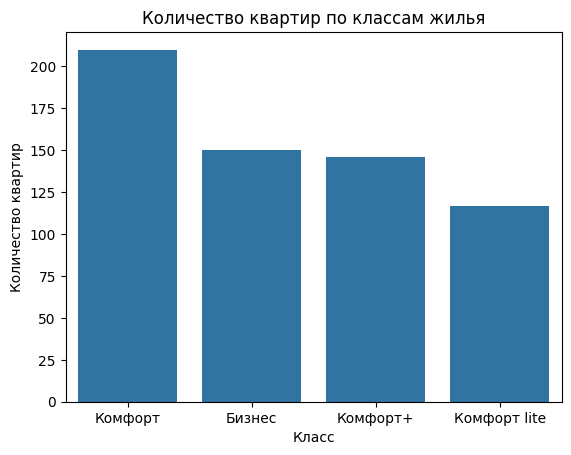

In [6]:
# Визуализации (на очищенных данных)
sns.countplot(data=df, x='class', order=df['class'].value_counts().index)
plt.title('Количество квартир по классам жилья')
plt.xlabel('Класс')
plt.ylabel('Количество квартир')
plt.show()

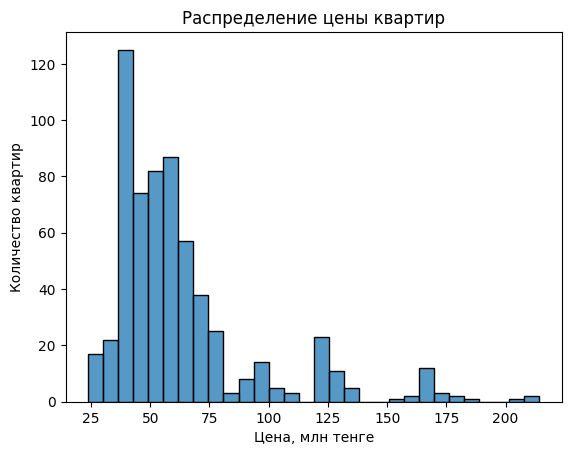

In [7]:
# Распределение цены
sns.histplot(df['price_m'], bins=30)
plt.title('Распределение цены квартир')
plt.xlabel('Цена, млн тенге')
plt.ylabel('Количество квартир')
plt.show()

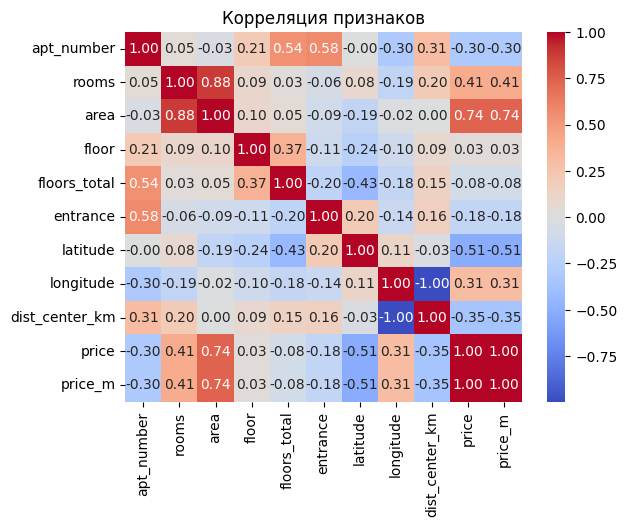

In [8]:
# Корреляция признаков с ценой
sns.heatmap(df.corr(numeric_only=True), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Корреляция признаков')
plt.show()

# Выбор признаков и кодирование

In [9]:
# Подготовка признаков
features = ['rooms', 'area', 'floor', 'floors_total', 'entrance',
            'latitude', 'longitude', 'dist_center_km', 'class']
X = pd.get_dummies(df[features], columns=['class'], dtype=int)
y = df['price_m']
print(X.columns.tolist())

['rooms', 'area', 'floor', 'floors_total', 'entrance', 'latitude', 'longitude', 'dist_center_km', 'class_Бизнес', 'class_Комфорт', 'class_Комфорт lite', 'class_Комфорт+']


In [10]:
# Разделение на обучающую и тестовую выборки
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print('X_train:', X_train.shape)
print('X_test:', X_test.shape)
print('y_train:', y_train.shape)
print('y_test:', y_test.shape)

X_train: (498, 12)
X_test: (125, 12)
y_train: (498,)
y_test: (125,)


1. **Сколько объектов используется для обучения?**
Ответ: 498 квартир (80%).

2. **Сколько объектов используется для тестирования?**
Ответ: 125 квартир (20%).

3. **Для чего нужен параметр stratify=y?**
Ответ: он сохраняет одинаковую долю каждого класса в обеих выборках. В классификации это важно, особенно при несбалансированных классах. В нашей регрессии целевая переменная непрерывная, классов нет, поэтому stratify не используется (его можно применить только к категориальному признаку, например к class).

# KNN

In [11]:
#KNN без масштабирования (k = 5)
# Функция для расчёта метрик регрессии
def evaluate(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    return mae, rmse, r2

knn_without_scaling = KNeighborsRegressor(n_neighbors=5)
knn_without_scaling.fit(X_train, y_train)
pred_without_scaling = knn_without_scaling.predict(X_test)

mae_1, rmse_1, r2_1 = evaluate(y_test, pred_without_scaling)
print(f'Без масштабирования: MAE={mae_1:.2f}, RMSE={rmse_1:.2f}, R2={r2_1:.3f}')

Без масштабирования: MAE=3.50, RMSE=5.61, R2=0.970


Метрики, которые мы теперь используем:

MAE — средняя ошибка в миллионах тенге;


RMSE — похожа на MAE, но сильнее штрафует большие промахи;


R² — какую долю разброса цен объясняет модель (1 — идеально).




In [12]:
# Масштабирование признаков (fit только на train)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [13]:
# KNN (k=5) после масштабирования и сравнение
knn_scaled = KNeighborsRegressor(n_neighbors=5)
knn_scaled.fit(X_train_scaled, y_train)
pred_scaled = knn_scaled.predict(X_test_scaled)

mae_2, rmse_2, r2_2 = evaluate(y_test, pred_scaled)

comparison = pd.DataFrame({
    'Вариант': ['Без масштабирования', 'После масштабирования'],
    'MAE': [mae_1, mae_2],
    'RMSE': [rmse_1, rmse_2],
    'R2': [r2_1, r2_2]
})
comparison.round(3)

,Вариант,MAE,RMSE,R2
0,Без масштабирования,3.502,5.611,0.970
1,После масштабирования,3.742,5.283,0.973


1. **Изменился ли результат после масштабирования?**
Ответ: да, но результат смешанный. RMSE снизилась с 5,61 до 5,28 млн, а R² выросла с 0,970 до 0,973. Но MAE немного ухудшилась (с 3,50 до 3,74 млн). То есть масштабирование уменьшило крупные промахи, но на «обычных» квартирах стало чуть менее точным.

2. **Почему масштабирование важно для KNN?**
Ответ: KNN ищет соседей по расстоянию. Без масштабирования признак с большими числами (площадь 28–159 м², долгота 76,79) перевешивает признаки с малыми (комнаты 1–4, 0/1 для класса), и «похожесть» считается неправильно. После StandardScaler все признаки имеют среднее 0 и разброс 1, и каждый вносит сопоставимый вклад.

3. **Какой вариант показал лучший результат?**
Ответ: по RMSE и R² лучше вариант с масштабированием, поэтому дальше работаем с ним. Для главной метрики я выбираю RMSE, потому что для цены на недвижимость крупные ошибки особенно неприятны.

In [14]:
# Перебор k от 1 до 20
results = []
for k in range(1, 21):
    model = KNeighborsRegressor(n_neighbors=k)
    model.fit(X_train_scaled, y_train)
    predictions = model.predict(X_test_scaled)
    mae, rmse, r2 = evaluate(y_test, predictions)
    results.append({'k': k, 'MAE': mae, 'RMSE': rmse, 'R2': r2})

results_df = pd.DataFrame(results)
results_df.round(3)

,k,MAE,RMSE,R2
0,1,4.241,6.706,0.957
1,2,3.691,5.687,0.969
2,3,3.634,5.433,0.972
3,4,3.671,5.261,0.973
4,5,3.742,5.283,0.973
5,6,3.782,5.367,0.972
6,7,3.941,5.502,0.971
7,8,4.057,5.637,0.969
8,9,4.116,5.705,0.969
9,10,4.180,5.810,0.967


In [15]:
# Лучший результат (минимальная RMSE)
best_result = results_df.loc[results_df['RMSE'].idxmin()]
print(best_result)

k       4.000000
MAE     3.670562
RMSE    5.260576
R2      0.973304
Name: 3, dtype: float64


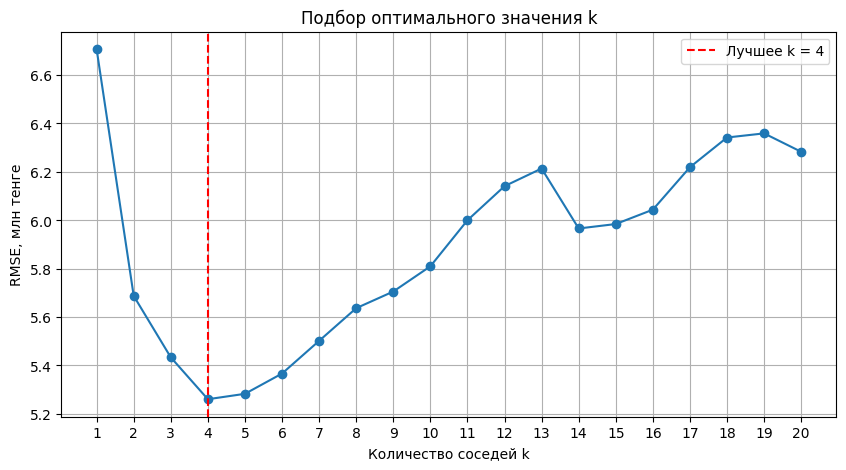

In [16]:
# График зависимости RMSE от k
best_k = int(best_result['k'])

plt.figure(figsize=(10, 5))
plt.plot(results_df['k'], results_df['RMSE'], marker='o')
plt.axvline(best_k, color='red', linestyle='--', label=f'Лучшее k = {best_k}')
plt.xticks(range(1, 21))
plt.xlabel('Количество соседей k')
plt.ylabel('RMSE, млн тенге')
plt.title('Подбор оптимального значения k')
plt.legend()
plt.grid()
plt.show()

1. **При каком значении k получена лучшая метрика?**
Ответ: при k = 4: RMSE = 5,26 млн, MAE = 3,67 млн, R² = 0,973. По MAE чуть лучше k = 3 (3,63 млн), но разница минимальная.

2. **Одинаковый ли результат получился для разных значений k?**
Ответ: нет. При k = 1 RMSE равна 6,71, к k = 4 падает до 5,26, а дальше растёт примерно до 6,3 при k = 20. Лучше всего работает небольшой диапазон k = 3–6.

3. **Почему нельзя всегда использовать k = 1?**
Ответ: при k = 1 цена берётся у единственной самой похожей квартиры, поэтому модель повторяет любые случайности и выбросы обучающей выборки (переобучение). Это видно по результату: RMSE при k = 1 хуже, чем при k = 4. Слишком большое k тоже плохо: цена усредняется по слишком разным квартирам, и модель сглаживает важные различия.

In [17]:
# Обучение итоговой модели
print('Лучшее значение k:', best_k)

final_knn = KNeighborsRegressor(n_neighbors=best_k)
final_knn.fit(X_train_scaled, y_train)
final_predictions = final_knn.predict(X_test_scaled)

mae, rmse, r2 = evaluate(y_test, final_predictions)
print(f'MAE  = {mae:.2f} млн тенге')
print(f'RMSE = {rmse:.2f} млн тенге')
print(f'R2   = {r2:.3f}')

Лучшее значение k: 4
MAE  = 3.67 млн тенге
RMSE = 5.26 млн тенге
R2   = 0.973


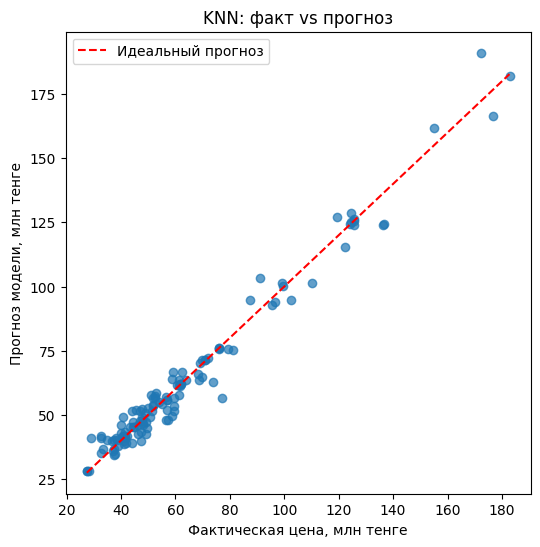

In [18]:
# График "факт vs прогноз"
plt.figure(figsize=(6, 6))
plt.scatter(y_test, final_predictions, alpha=0.7)
lims = [y_test.min(), y_test.max()]
plt.plot(lims, lims, 'r--', label='Идеальный прогноз')
plt.xlabel('Фактическая цена, млн тенге')
plt.ylabel('Прогноз модели, млн тенге')
plt.title('KNN: факт vs прогноз')
plt.legend()
plt.show()

count    125.000000
mean       3.670562
std        3.783537
min        0.000000
25%        0.690760
50%        2.401635
75%        5.591350
max       20.512520
Name: price_m, dtype: float64
MAE дорогих (топ-10% цен): 5.738253461538464
MAE остальных: 3.430562033482143


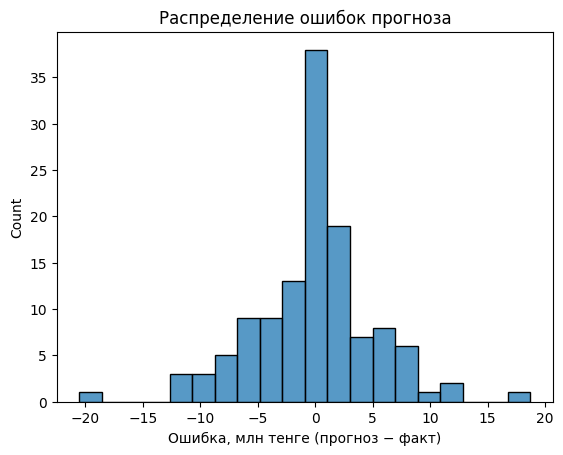

In [19]:
# Распределение ошибок и ошибка для дорогих квартир
errors = final_predictions - y_test
print(errors.abs().describe())

expensive = y_test > y_test.quantile(0.9)
print('MAE дорогих (топ-10% цен):', errors[expensive].abs().mean())
print('MAE остальных:', errors[~expensive].abs().mean())

sns.histplot(errors, bins=20)
plt.title('Распределение ошибок прогноза')
plt.xlabel('Ошибка, млн тенге (прогноз − факт)')
plt.show()

1. **Сколько объектов модель определила правильно?**
Ответ: в регрессии «правильно или нет» не бывает, мы смотрим на размер ошибки. Для половины из 125 тестовых квартир ошибка не больше 2,4 млн (медиана), а для четверти — меньше 0,7 млн. Медианная относительная ошибка составляет около 4,3% от цены.

2. **Какие объекты модель «перепутала»?**
Ответ: хуже всего модель предсказывает дорогие квартиры. Для топ-10% по цене средняя ошибка 5,74 млн, для остальных 3,43 млн. Максимальный промах — 20,5 млн. Причина в том, что дорогих квартир (в основном класс «Бизнес», до 214 млн) в данных мало и у них мало похожих соседей.

3. **Какое итоговое качество получено?**
Ответ: R² = 0,973, то есть модель объясняет около 97% разброса цен. Средняя ошибка 3,67 млн при средней цене в тесте около 64 млн.

# Линейная регрессия

In [20]:
# Создание модели линейной регрессии
model = LinearRegression()

In [21]:
# Обучение модели на обучающей выборке
model.fit(X_train, y_train)

LinearRegression()

In [22]:
# Получение прогнозов для тестовой выборки
predictions = model.predict(X_test)
print(predictions[:10].round(2))

[73.88 68.64 36.78 20.47 80.79 50.65 22.22 52.74 84.2  76.44]


In [23]:
# Сравнение прогнозов с правильными значениями
pred_table = pd.DataFrame({
    'Правильное значение': y_test.values,
    'Прогноз модели': predictions
})
pred_table.head(10)

,Правильное значение,Прогноз модели
0,56.46405,73.880118
1,59.13320,68.637847
2,49.06962,36.780257
3,28.14264,20.467866
4,70.83320,80.786929
5,44.43138,50.651268
6,27.41544,22.221819
7,46.91358,52.743471
8,79.20948,84.204558
9,77.13856,76.442861


In [24]:
# Добавление абсолютной ошибки
pred_table['Ошибка'] = abs(pred_table['Правильное значение'] - pred_table['Прогноз модели'])
pred_table.head(10)

,Правильное значение,Прогноз модели,Ошибка
0,56.46405,73.880118,17.416068
1,59.13320,68.637847,9.504647
2,49.06962,36.780257,12.289363
3,28.14264,20.467866,7.674774
4,70.83320,80.786929,9.953729
5,44.43138,50.651268,6.219888
6,27.41544,22.221819,5.193621
7,46.91358,52.743471,5.829891
8,79.20948,84.204558,4.995078
9,77.13856,76.442861,0.695699


In [25]:
# Расчёт метрик MAE, RMSE, R²
lin_mae = mean_absolute_error(y_test, predictions)
lin_rmse = np.sqrt(mean_squared_error(y_test, predictions))
lin_r2 = r2_score(y_test, predictions)

print('MAE:', round(lin_mae, 3))
print('RMSE:', round(lin_rmse, 3))
print('R²:', round(lin_r2, 3))

MAE: 6.677
RMSE: 8.147
R²: 0.936


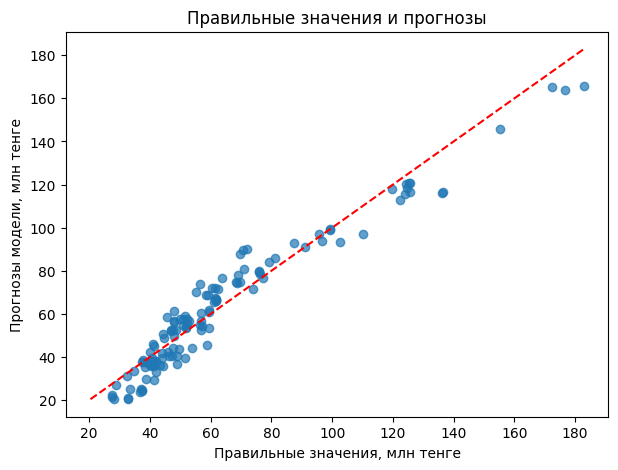

In [26]:
# График "правильные значения и прогнозы"
plt.figure(figsize=(7, 5))
plt.scatter(y_test, predictions, alpha=0.7)
plt.xlabel('Правильные значения, млн тенге')
plt.ylabel('Прогнозы модели, млн тенге')
plt.title('Правильные значения и прогнозы')
minimum = min(y_test.min(), predictions.min())
maximum = max(y_test.max(), predictions.max())
plt.plot([minimum, maximum], [minimum, maximum], color='red', linestyle='--')
plt.show()

In [27]:
# Квартиры с самыми большими ошибками
pred_table = pred_table.sort_values(by='Ошибка', ascending=False)
pred_table.head(10)

,Правильное значение,Прогноз модели,Ошибка
45,136.10806,116.109976,19.998084
80,136.53398,116.727563,19.806417
106,70.76000,89.437181,18.677181
93,71.92000,90.333839,18.413839
88,69.70005,87.893471,18.193421
0,56.46405,73.880118,17.416068
43,182.79441,165.731585,17.062825
25,55.04400,69.984846,14.940846
72,47.78910,61.537402,13.748302
100,37.29888,24.101984,13.196896


In [28]:
# Дополнительно: сколько больших ошибок и ошибка для дорогих квартир
print('Ошибок больше 10 млн:', (pred_table['Ошибка'] > 10).sum(), 'из', len(pred_table))
expensive = pred_table['Правильное значение'] > pred_table['Правильное значение'].quantile(0.9)
print('MAE дорогих (топ-10% цен):', round(pred_table.loc[expensive, 'Ошибка'].mean(), 2))
print('MAE остальных:', round(pred_table.loc[~expensive, 'Ошибка'].mean(), 2))

Ошибок больше 10 млн: 25 из 125
MAE дорогих (топ-10% цен): 10.27
MAE остальных: 6.26


1. **Какое значение MAE получено?**
Ответ: MAE = 6,68 млн тенге. В среднем модель ошибается в цене квартиры примерно на 6,7 млн тенге.

2. **Есть ли у модели очень большие ошибки?**
Ответ: да. Максимальная ошибка почти 20 млн тенге (RMSE = 8,15 больше MAE = 6,68, значит, есть заметные выбросы). Ошибка больше 10 млн получилась у 25 из 125 тестовых квартир.

3. **Для каких объектов модель ошибается сильнее?**
Ответ: для дорогих квартир и для больших квартир в более дешёвых ЖК. Средняя ошибка для топ-10% по цене 10,27 млн, для остальных 6,26 млн. Самые большие недооценки у квартир класса «Бизнес» в Taumura (около 136 млн, ошибка около 20 млн). Самые большие завышения у квартир площадью около 110–116 м² в ЖК Arena City Balance и Jibek Joly, где модель завысила цену на 15–19 млн. Линейная модель считает, что стоимость одного квадратного метра везде примерно одинакова, а на деле она сильно зависит от ЖК и класса.

4. **Можно ли использовать такую модель на практике?**
Ответ: только для грубой оценки. Типичная ошибка составляет около 9% от цены, что приемлемо для ориентировочного прогноза, но слишком много для точной оценки сделки. Для практики лучше использовать более точную модель, например KNN из практики №9 (MAE 3,67 млн).

In [29]:
# Простая модель: всегда предсказывает среднюю цену
from sklearn.dummy import DummyRegressor
dummy_model = DummyRegressor(strategy='mean')
dummy_model.fit(X_train, y_train)
dummy_predictions = dummy_model.predict(X_test)

dummy_mae = mean_absolute_error(y_test, dummy_predictions)
dummy_rmse = np.sqrt(mean_squared_error(y_test, dummy_predictions))
dummy_r2 = r2_score(y_test, dummy_predictions)

print('MAE простой модели:', round(dummy_mae, 3))
print('MAE обученной модели:', round(lin_mae, 3))

MAE простой модели: 23.265
MAE обученной модели: 6.677


In [30]:
# Таблица сравнения с простой моделью
baseline_table = pd.DataFrame({
    'Модель': ['Простой прогноз (среднее)', 'Линейная регрессия'],
    'MAE': [dummy_mae, lin_mae],
    'RMSE': [dummy_rmse, lin_rmse],
    'R2': [dummy_r2, lin_r2]
})
baseline_table.round(3)

,Модель,MAE,RMSE,R2
0,Простой прогноз (среднее),23.265,32.201,-0.000
1,Линейная регрессия,6.677,8.147,0.936


1. **Оказалась ли обученная модель лучше простой модели?**
Ответ: да, значительно. Простая модель всегда предсказывает среднюю цену (около 63,4 млн) и поэтому имеет R² около 0, то есть ничего не объясняет. Линейная регрессия объясняет около 94% разброса цен.

2. **Насколько отличается результат?**
Ответ: MAE снизилась с 23,27 млн до 6,68 млн, то есть почти в 3,5 раза (примерно на 71%). RMSE снизилась с 32,20 млн до 8,15 млн.

3. **Имеет ли смысл дальнейшее улучшение модели?**
Ответ: да. Ошибка в 6,68 млн всё ещё велика для квартир со средней ценой около 64 млн, особенно для дорогих квартир. Улучшить можно, например, моделью KNN (в практике №9 она дала MAE 3,67 млн), деревом решений или ансамблем, а также добавлением признаков.

# Дерево решений

In [31]:
# Дерево без ограничения глубины
from sklearn.tree import DecisionTreeRegressor, plot_tree
tree_full = DecisionTreeRegressor(random_state=42)
tree_full.fit(X_train, y_train)

train_mae, train_rmse, train_r2 = evaluate(y_train, tree_full.predict(X_train))
test_mae, test_rmse, test_r2 = evaluate(y_test, tree_full.predict(X_test))

print(f'Обучение:    MAE={train_mae:.3f}, RMSE={train_rmse:.3f}, R2={train_r2:.4f}')
print(f'Тестирование: MAE={test_mae:.3f}, RMSE={test_rmse:.3f}, R2={test_r2:.4f}')
print('Глубина дерева:', tree_full.get_depth())
print('Количество листьев:', tree_full.get_n_leaves())

Обучение:    MAE=0.012, RMSE=0.161, R2=1.0000
Тестирование: MAE=2.811, RMSE=5.426, R2=0.9716
Глубина дерева: 17
Количество листьев: 399


1. **Какое качество модель показала на обучающей выборке?**
Ответ: практически идеальное: MAE = 0,012 млн, RMSE = 0,161 млн, R² = 0,99997.

2. **Какое качество она показала на тестовой выборке?**
Ответ: MAE = 2,74 млн, RMSE = 5,42 млн, R² = 0,972. Глубина дерева 17, листьев 400.

3. **Почему результат на обучении может быть выше?**
Ответ: модель видела обучающие данные при обучении. Дерево без ограничений делит данные, пока почти каждая квартира не окажется в своём листе (399 листьев на 498 объектов), то есть фактически запоминает ответы.

4. **Можно ли предположить наличие переобучения?**
Ответ: да. Ошибка RMSE на обучении 0,16 млн, а на тесте 5,42 млн, то есть в 30 раз больше. Дерево запомнило обучающие данные и хуже работает на новых.

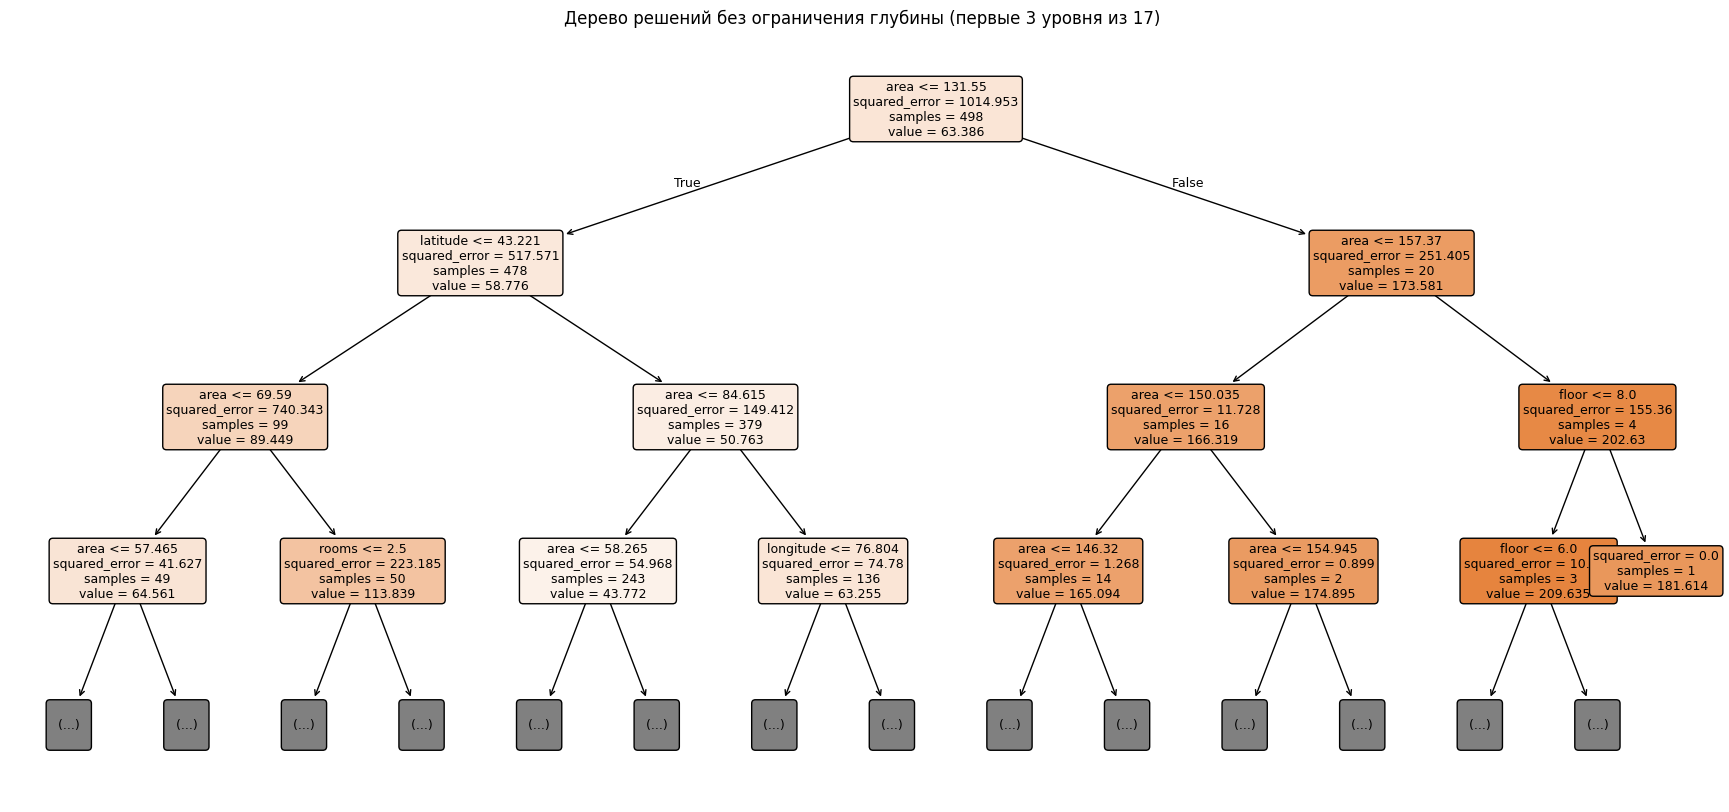

In [32]:
# Визуализация дерева (показаны первые 3 уровня)
plt.figure(figsize=(22, 10))
plot_tree(
    tree_full,
    max_depth=3,
    feature_names=X.columns,
    filled=True,
    rounded=True,
    fontsize=9
)
plt.title('Дерево решений без ограничения глубины (первые 3 уровня из 17)')
plt.show()

1. **Какой признак используется в первом разделении?**
Ответ: area (площадь квартиры).

2. **Какое условие указано в корневом узле?**
Ответ: area <= 131,55 м². Квартиры меньшей площади идут в левую ветку, большей — в правую.

3. **Сколько уровней имеет дерево?**
Ответ: 17 уровней, 399 листьев.

4. **Легко ли человеку объяснить такое дерево?**
Ответ: нет. Верхние уровни понятны (сначала делим по площади, потом по расположению ЖК), но цепочки из 17 условий и 400 листьев объяснить невозможно.

In [33]:
# Дерево с max_depth=3
tree_depth_3 = DecisionTreeRegressor(max_depth=3, random_state=42)
tree_depth_3.fit(X_train, y_train)

train_mae_3, train_rmse_3, train_r2_3 = evaluate(y_train, tree_depth_3.predict(X_train))
test_mae_3, test_rmse_3, test_r2_3 = evaluate(y_test, tree_depth_3.predict(X_test))

print(f'Обучение:  MAE={train_mae_3:.3f}, RMSE={train_rmse_3:.3f}, R2={train_r2_3:.3f}')
print(f'Тест:      MAE={test_mae_3:.3f}, RMSE={test_rmse_3:.3f}, R2={test_r2_3:.3f}')
print('Глубина дерева:', tree_depth_3.get_depth())
print('Количество листьев:', tree_depth_3.get_n_leaves())

Обучение:  MAE=6.734, RMSE=8.594, R2=0.927
Тест:      MAE=8.350, RMSE=10.671, R2=0.890
Глубина дерева: 3
Количество листьев: 8


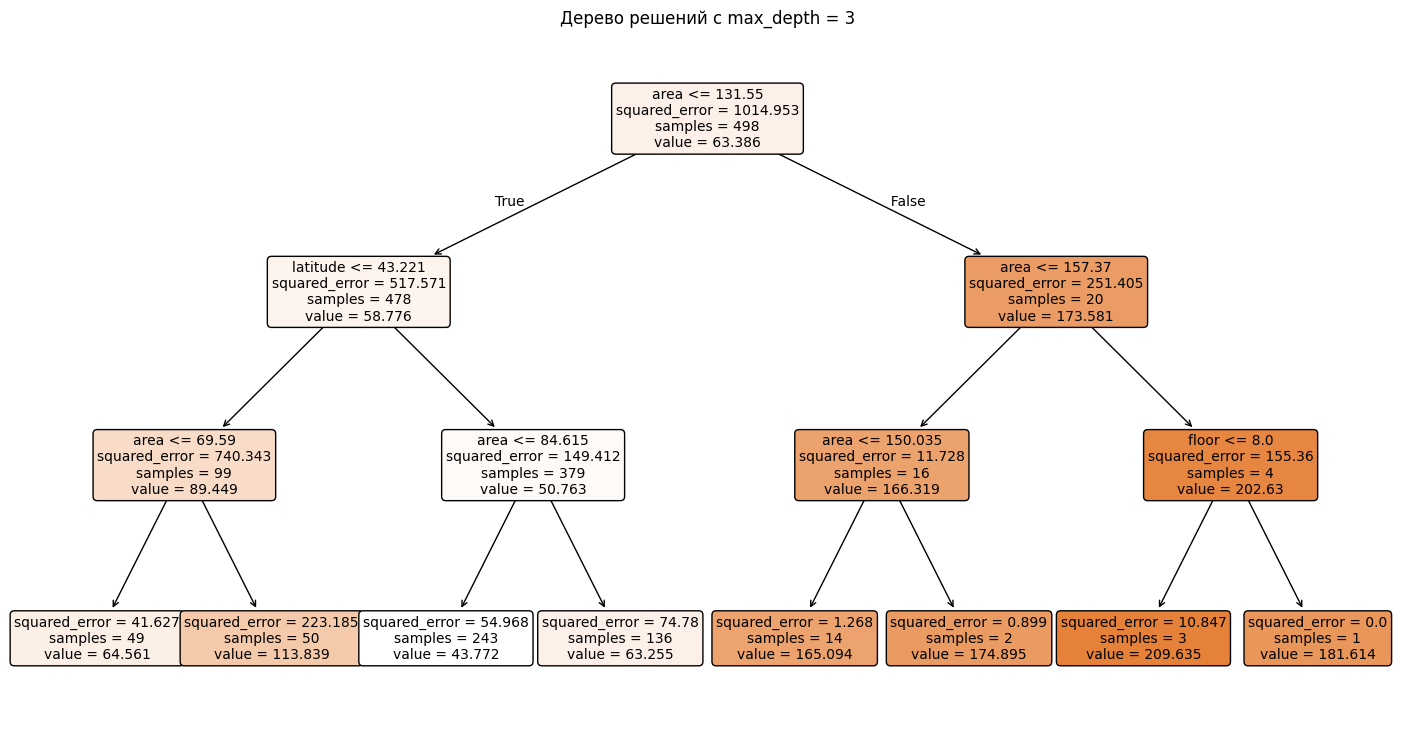

In [34]:
# Визуализация дерева с max_depth=3
plt.figure(figsize=(18, 9))
plot_tree(
    tree_depth_3,
    feature_names=X.columns,
    filled=True,
    rounded=True,
    fontsize=10
)
plt.title('Дерево решений с max_depth = 3')
plt.show()

1. **Стало ли дерево понятнее?**
Ответ: да. В нём всего 3 уровня и 8 листьев, и его можно прочитать: сначала делим по площади (131,55 м²), потом по широте, то есть по расположению ЖК, и снова по площади.

2. **Изменилась ли точность?**
Ответ: да, стала заметно хуже. На тесте MAE = 8,35 млн, RMSE = 10,67 млн, R² = 0,890. У полного дерева MAE = 2,74 млн, RMSE = 5,42 млн, R² = 0,972.

3. **Какая модель лучше работает на тестовой выборке?**
Ответ: полное дерево (RMSE 5,42 против 10,67 млн). Дерево с глубиной 3 слишком простое (недообучение): у него и на обучении ошибка большая (RMSE 8,59 млн, R² 0,927).

4. **Как ограничение глубины влияет на переобучение?**
Ответ: ограничение уменьшает переобучение: разница между обучением и тестом у дерева глубины 3 небольшая (RMSE 8,59 и 10,67 против 0,16 и 5,42 у полного). Но слишком сильное ограничение даёт недообучение, поэтому глубину нужно подбирать.

In [35]:
# Перебор глубины дерева от 1 до 10
tree_results = []
for depth in range(1, 11):
    model_d = DecisionTreeRegressor(max_depth=depth, random_state=42)
    model_d.fit(X_train, y_train)
    _, train_rmse, _ = evaluate(y_train, model_d.predict(X_train))
    test_mae, test_rmse, test_r2 = evaluate(y_test, model_d.predict(X_test))
    tree_results.append({
        'Глубина': depth,
        'RMSE на обучении': train_rmse,
        'RMSE на тесте': test_rmse,
        'MAE на тесте': test_mae,
        'R2 на тесте': test_r2
    })

tree_results_df = pd.DataFrame(tree_results)
tree_results_df.round(3)

,Глубина,RMSE на обучении,RMSE на тесте,MAE на тесте,R2 на тесте
0,1,22.514,25.585,18.542,0.369
1,2,16.202,17.134,13.433,0.717
2,3,8.594,10.671,8.350,0.890
3,4,5.223,6.837,5.045,0.955
4,5,3.716,5.880,4.010,0.967
5,6,3.061,5.453,3.530,0.971
6,7,2.484,5.245,3.255,0.973
7,8,2.055,5.102,2.999,0.975
8,9,1.726,5.301,2.944,0.973
9,10,1.438,5.120,2.826,0.975


In [36]:
# Лучшая глубина (минимальная RMSE на тесте)
best_tree_result = tree_results_df.loc[tree_results_df['RMSE на тесте'].idxmin()]
print(best_tree_result)

Глубина             8.000000
RMSE на обучении    2.054516
RMSE на тесте       5.102085
MAE на тесте        2.999049
R2 на тесте         0.974888
Name: 7, dtype: float64


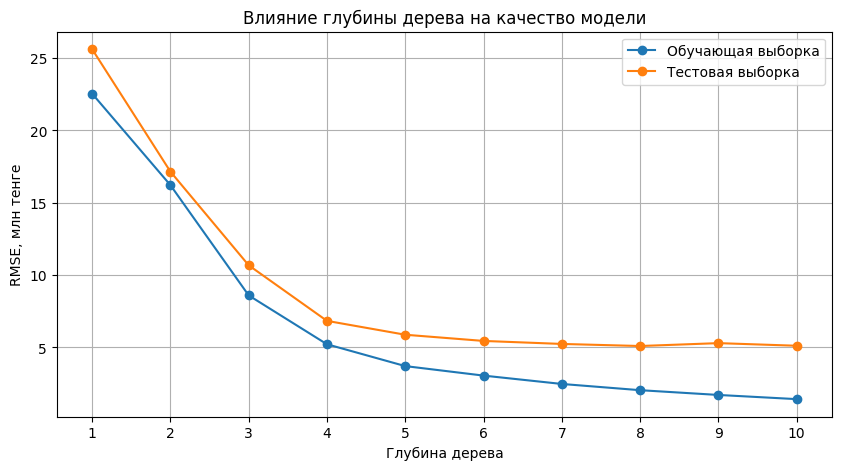

In [37]:
# График влияния глубины на качество
plt.figure(figsize=(10, 5))
plt.plot(tree_results_df['Глубина'], tree_results_df['RMSE на обучении'], marker='o', label='Обучающая выборка')
plt.plot(tree_results_df['Глубина'], tree_results_df['RMSE на тесте'], marker='o', label='Тестовая выборка')
plt.xlabel('Глубина дерева')
plt.ylabel('RMSE, млн тенге')
plt.title('Влияние глубины дерева на качество модели')
plt.xticks(range(1, 11))
plt.legend()
plt.grid()
plt.show()

1. **При какой глубине получена лучшая метрика на тесте?**
Ответ: при глубине 10: RMSE = 5,08 млн, MAE = 2,79 млн, R² = 0,975. Но результат почти такой же уже при глубине 7–8 (RMSE 5,25 и 5,10), то есть после глубины 7 качество практически не растёт.

2. **Как изменяется результат на обучающей выборке при увеличении глубины?**
Ответ: ошибка постоянно уменьшается: RMSE падает с 22,5 млн при глубине 1 до 1,44 млн при глубине 10.

3. **С какого момента появляется разница между обучением и тестированием?**
Ответ: заметная разница видна уже с глубины 4–5 (RMSE 3,72 на обучении и 5,88 на тесте при глубине 5). С глубины 7 ошибка на тесте почти перестаёт улучшаться, а на обучении продолжает падать.

4. **Как эта разница связана с переобучением?**
Ответ: когда ошибка на обучении продолжает падать, а на тесте не улучшается, модель начинает запоминать частные случаи обучающей выборки вместо общих закономерностей. Это и есть переобучение. При глубине 10 ошибка на обучении (1,44 млн) более чем в 3 раза меньше, чем на тесте (5,08 млн).

In [38]:
# Обучение итогового дерева с лучшей глубиной
best_depth = int(best_tree_result['Глубина'])
print('Оптимальная глубина:', best_depth)

final_tree = DecisionTreeRegressor(max_depth=best_depth, random_state=42)
final_tree.fit(X_train, y_train)
tree_predictions = final_tree.predict(X_test)

tree_mae, tree_rmse, tree_r2 = evaluate(y_test, tree_predictions)
print(f'MAE  = {tree_mae:.2f} млн тенге')
print(f'RMSE = {tree_rmse:.2f} млн тенге')
print(f'R2   = {tree_r2:.3f}')

Оптимальная глубина: 8
MAE  = 3.00 млн тенге
RMSE = 5.10 млн тенге
R2   = 0.975


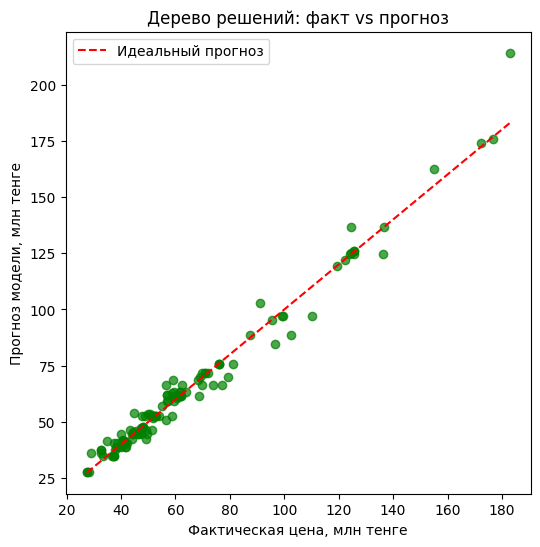

In [39]:
# График "факт vs прогноз" для итогового дерева
plt.figure(figsize=(6, 6))
plt.scatter(y_test, tree_predictions, alpha=0.7, color='green')
lims = [y_test.min(), y_test.max()]
plt.plot(lims, lims, 'r--', label='Идеальный прогноз')
plt.xlabel('Фактическая цена, млн тенге')
plt.ylabel('Прогноз модели, млн тенге')
plt.title('Дерево решений: факт vs прогноз')
plt.legend()
plt.show()

count    125.000000
mean       2.999049
std        4.144197
min        0.000000
25%        0.490699
50%        1.494779
75%        3.932505
max       31.346940
Name: price_m, dtype: float64
Ошибок больше 10 млн: 9 из 125
MAE дорогих (топ-10% цен): 5.21
MAE остальных: 2.74


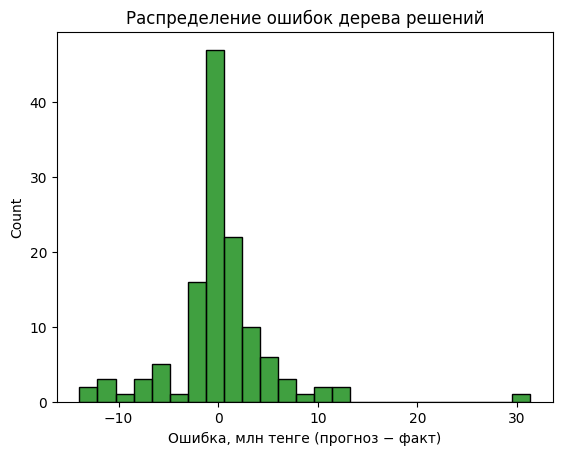

In [40]:
# Распределение ошибок
tree_errors = tree_predictions - y_test
print(tree_errors.abs().describe())

expensive = y_test > y_test.quantile(0.9)
print('Ошибок больше 10 млн:', (tree_errors.abs() > 10).sum(), 'из', len(tree_errors))
print('MAE дорогих (топ-10% цен):', round(tree_errors[expensive].abs().mean(), 2))
print('MAE остальных:', round(tree_errors[~expensive].abs().mean(), 2))

sns.histplot(tree_errors, bins=25, color='green')
plt.title('Распределение ошибок дерева решений')
plt.xlabel('Ошибка, млн тенге (прогноз − факт)')
plt.show()

1. Сколько объектов модель определила правильно?
Ответ: в регрессии «правильно или неправильно» не бывает, смотрят на размер ошибки. Для половины тестовых квартир ошибка не больше 1,13 млн (медиана), для четверти — меньше 0,3 млн. Ошибок больше 10 млн всего 9 из 125.

2. Какие объекты модель перепутала?
Ответ: хуже всего прогнозируются дорогие квартиры. Для топ-10% по цене средняя ошибка 5,34 млн, для остальных 2,50 млн. Максимальный промах — 31,3 млн.

3. Какие объекты определяются лучше всего?
Ответ: квартиры средней и низкой цены, для которых в обучающей выборке много похожих объектов в том же ЖК. Ошибка там в среднем около 2,5 млн.

4. Какие объекты вызывают больше ошибок?
Ответ: дорогие и нетипичные квартиры (большая площадь, класс «Бизнес»). Таких квартир в данных мало, поэтому в их листьях мало объектов, и прогноз получается нестабильным.

In [41]:
# Важность признаков итогового дерева
feature_importance = pd.DataFrame({
    'Признак': X.columns,
    'Важность': final_tree.feature_importances_
}).sort_values(by='Важность', ascending=False)

feature_importance.round(4)

,Признак,Важность
1,area,0.7305
5,latitude,0.2430
0,rooms,0.0197
2,floor,0.0041
7,dist_center_km,0.0016
4,entrance,0.0006
6,longitude,0.0003
9,class_Комфорт,0.0001
3,floors_total,0.0001
8,class_Бизнес,0.0000


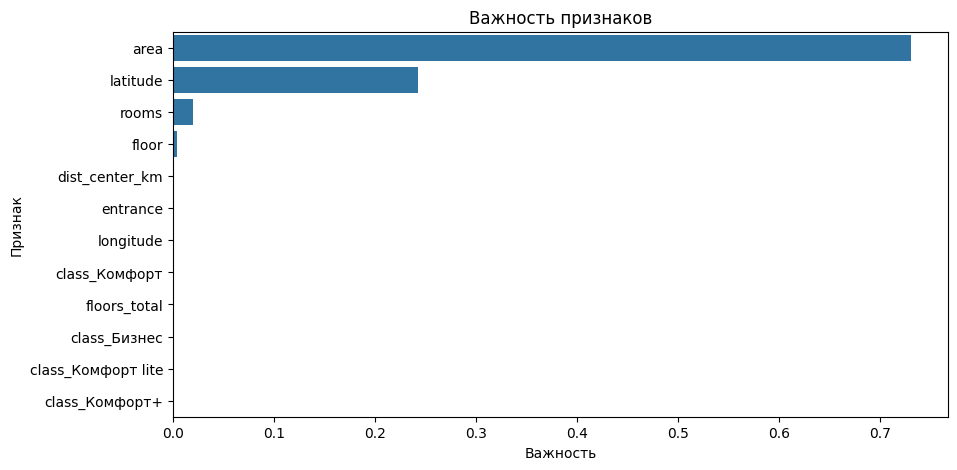

In [42]:
# График важности признаков
plt.figure(figsize=(10, 5))
sns.barplot(data=feature_importance, x='Важность', y='Признак')
plt.title('Важность признаков')
plt.show()

1. **Какой признак оказался самым важным?**
Ответ: area (площадь), важность 0,75. Второй по важности latitude (широта), 0,23. Вместе они объясняют около 98% решений дерева.

2. **Какие признаки практически не использовались?**
Ответ: floors_total, rooms, entrance, все столбцы class и longitude (важность меньше 0,003). Комнаты и класс жилья не нужны дереву, потому что информацию о них уже несут площадь (чем больше площадь, тем больше комнат) и широта (она одинакова для всех квартир одного ЖК, а класс определяется ЖК).

3. **Можно ли считать важность признака доказательством причины результата?**
Ответ: нет. Важность показывает только, какие признаки модель чаще использовала для деления, а не что именно они вызывают рост цены. Например, широта важна не сама по себе, а потому что определяет ЖК, а у каждого ЖК свой уровень цен.

4. **Чем важность признаков полезна для объяснения модели?**
Ответ: она показывает, на что опирается модель, помогает объяснить прогноз заказчику, найти ненужные признаки (их можно убрать) и проверить, что модель использует логичные признаки. В нашем случае цена определяется в первую очередь площадью и местоположением ЖК.

# RandomForest(случайный лес)

In [43]:
# Импорт Random Forest и модуля для измерения времени
import time
from sklearn.ensemble import RandomForestRegressor

In [44]:
# Обучение Random Forest из 100 деревьев
random_forest = RandomForestRegressor(n_estimators=100, random_state=42)
random_forest.fit(X_train, y_train)

rf_train_pred = random_forest.predict(X_train)
rf_test_pred = random_forest.predict(X_test)

rf_train_mae, rf_train_rmse, rf_train_r2 = evaluate(y_train, rf_train_pred)
rf_test_mae, rf_test_rmse, rf_test_r2 = evaluate(y_test, rf_test_pred)

print(f'Обучение:  MAE={rf_train_mae:.3f}, RMSE={rf_train_rmse:.3f}, R2={rf_train_r2:.4f}')
print(f'Тест:      MAE={rf_test_mae:.3f}, RMSE={rf_test_rmse:.3f}, R2={rf_test_r2:.4f}')

Обучение:  MAE=0.777, RMSE=1.354, R2=0.9982
Тест:      MAE=2.823, RMSE=4.838, R2=0.9774


1. **Какой результат получен на обучающей выборке?**
Ответ: MAE = 0,77 млн, RMSE = 1,35 млн, R² = 0,998.

2. **Какой результат получен на тестовой выборке?**
Ответ: MAE = 2,83 млн, RMSE = 4,83 млн, R² = 0,977.

3. **Есть ли большая разница между результатами?**
Ответ: да, умеренная. RMSE на тесте (4,83) примерно в 3,6 раза больше, чем на обучении (1,35). Но для одного дерева без ограничений разница была в 33 раза (0,16 и 5,42), то есть лес ведёт себя заметно стабильнее.

4. **Можно ли предположить наличие переобучения?**
Ответ: небольшое переобучение есть: на обучении R² = 0,998, на тесте 0,977. Но на тестовой выборке результат всё равно высокий и лучше, чем у полного дерева (RMSE 4,83 против 5,42 млн), потому что усреднение 100 деревьев сглаживает случайные выбросы отдельных деревьев.

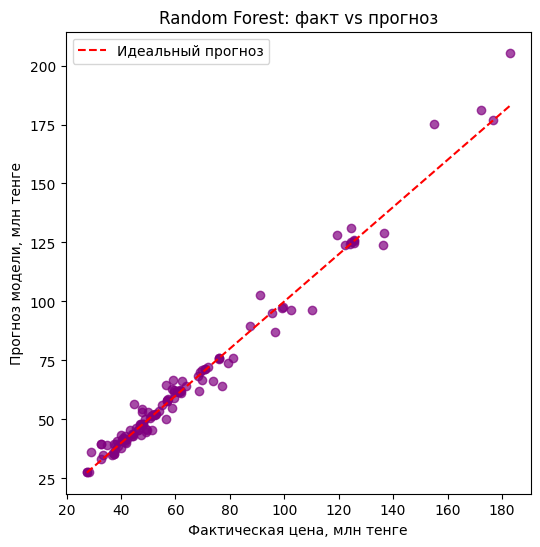

In [45]:
# График "факт vs прогноз" для Random Forest
plt.figure(figsize=(6, 6))
plt.scatter(y_test, rf_test_pred, alpha=0.7, color='purple')
lims = [y_test.min(), y_test.max()]
plt.plot(lims, lims, 'r--', label='Идеальный прогноз')
plt.xlabel('Фактическая цена, млн тенге')
plt.ylabel('Прогноз модели, млн тенге')
plt.title('Random Forest: факт vs прогноз')
plt.legend()
plt.show()

count    125.000000
mean       2.823181
std        3.945121
min        0.001569
25%        0.377475
50%        1.150429
75%        3.756316
max       22.633806
Name: price_m, dtype: float64
Ошибок больше 10 млн: 7 из 125
MAE дорогих (топ-10% цен): 6.26
MAE остальных: 2.42


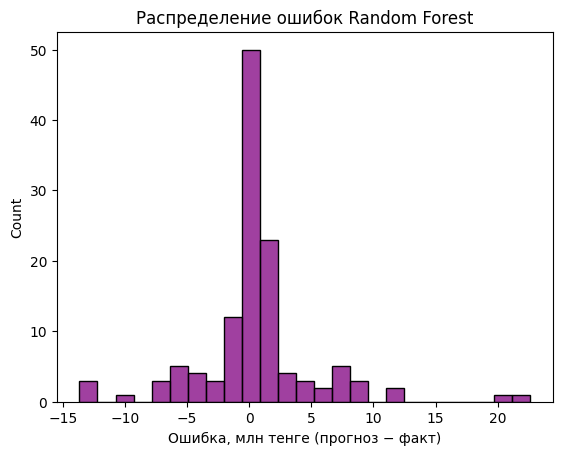

In [46]:
# Распределение ошибок
rf_errors = rf_test_pred - y_test
print(rf_errors.abs().describe())

expensive = y_test > y_test.quantile(0.9)
print('Ошибок больше 10 млн:', (rf_errors.abs() > 10).sum(), 'из', len(rf_errors))
print('MAE дорогих (топ-10% цен):', round(rf_errors[expensive].abs().mean(), 2))
print('MAE остальных:', round(rf_errors[~expensive].abs().mean(), 2))

sns.histplot(rf_errors, bins=25, color='purple')
plt.title('Распределение ошибок Random Forest')
plt.xlabel('Ошибка, млн тенге (прогноз − факт)')
plt.show()

1. **Сколько объектов классифицировано правильно?**
Ответ: в регрессии «правильно или неправильно» не бывает, смотрят на размер ошибки. Для половины тестовых квартир ошибка не больше 1,10 млн (медиана), для четверти — меньше 0,35 млн. Ошибок больше 10 млн только 7 из 125.

2. **Какие объекты модель перепутала?**
Ответ: хуже всего прогнозируются дорогие квартиры. Для топ-10% по цене средняя ошибка 6,26 млн, для остальных 2,43 млн. Максимальный промах — 22,7 млн.

3. **Какие объекты определяются лучше всего?**
Ответ: квартиры средней и низкой цены, у которых в данных много похожих объектов (ошибка в среднем около 2,4 млн).

4. **Какое качество показала модель?**
Ответ: R² = 0,977, MAE = 2,83 млн, RMSE = 4,83 млн. Модель объясняет около 98% разброса цен.

In [47]:
# Проверка разного количества деревьев
estimators_values = [10, 50, 100, 200, 300]
estimators_results = []

for n in estimators_values:
    start = time.time()
    model_n = RandomForestRegressor(n_estimators=n, random_state=42)
    model_n.fit(X_train, y_train)
    fit_time = time.time() - start
    mae, rmse, r2 = evaluate(y_test, model_n.predict(X_test))
    estimators_results.append({
        'Количество деревьев': n,
        'MAE': mae,
        'RMSE': rmse,
        'R2': r2,
        'Время обучения, с': fit_time
    })

estimators_df = pd.DataFrame(estimators_results)
estimators_df.round(3)

,Количество деревьев,MAE,RMSE,R2,"Время обучения, с"
0,10,2.815,4.916,0.977,0.084
1,50,2.794,4.913,0.977,0.304
2,100,2.823,4.838,0.977,0.610
3,200,2.827,4.824,0.978,0.971
4,300,2.856,4.895,0.977,0.999


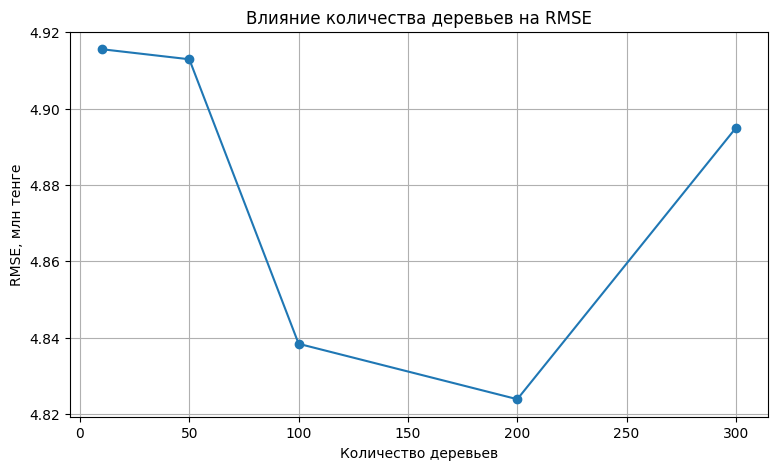

In [48]:
# График влияния количества деревьев
plt.figure(figsize=(9, 5))
plt.plot(estimators_df['Количество деревьев'], estimators_df['RMSE'], marker='o')
plt.xlabel('Количество деревьев')
plt.ylabel('RMSE, млн тенге')
plt.title('Влияние количества деревьев на RMSE')
plt.grid()
plt.show()

1. **При каком количестве деревьев получен лучший результат?**
Ответ: при 200 деревьях: RMSE = 4,83 млн, R² = 0,978. Но разница с 100 деревьями (RMSE 4,83) практически нулевая.

2. **Всегда ли увеличение числа деревьев повышает качество?**
Ответ: нет. С 10 до 100 деревьев RMSE немного улучшается (4,91 → 4,83), а дальше выходит на плато, и при 300 деревьях RMSE даже слегка вырос (4,89). Различия в сотых долях миллиона находятся на уровне случайного шума.

3. **Как количество деревьев влияет на скорость обучения?**
Ответ: время растёт примерно пропорционально числу деревьев (каждое дерево обучается отдельно). 300 деревьев обучаются заметно дольше, чем 10, а качество при этом почти не меняется.

4. **Какое количество деревьев вы выбрали бы?**
Ответ: 100–200. Формально лучший результат у 200 (его и берём дальше), а 100 деревьев дают почти то же качество и обучаются быстрее.

In [49]:
# Проверка глубины деревьев от 1 до 10 (n_estimators=100)
depth_results = []

for depth in range(1, 11):
    model_depth = RandomForestRegressor(n_estimators=100, max_depth=depth, random_state=42)
    model_depth.fit(X_train, y_train)
    _, train_rmse, _ = evaluate(y_train, model_depth.predict(X_train))
    test_mae, test_rmse, test_r2 = evaluate(y_test, model_depth.predict(X_test))
    depth_results.append({
        'Глубина': depth,
        'RMSE на обучении': train_rmse,
        'RMSE на тесте': test_rmse,
        'MAE на тесте': test_mae,
        'R2 на тесте': test_r2
    })

depth_df = pd.DataFrame(depth_results)
depth_df.round(3)

,Глубина,RMSE на обучении,RMSE на тесте,MAE на тесте,R2 на тесте
0,1,18.121,19.214,15.196,0.644
1,2,11.101,11.316,9.229,0.876
2,3,5.959,6.797,5.336,0.955
3,4,4.066,5.548,4.120,0.970
4,5,3.191,5.240,3.645,0.974
5,6,2.607,4.927,3.221,0.977
6,7,2.199,4.914,3.041,0.977
7,8,1.910,4.911,2.966,0.977
8,9,1.673,4.833,2.873,0.977
9,10,1.519,4.850,2.879,0.977


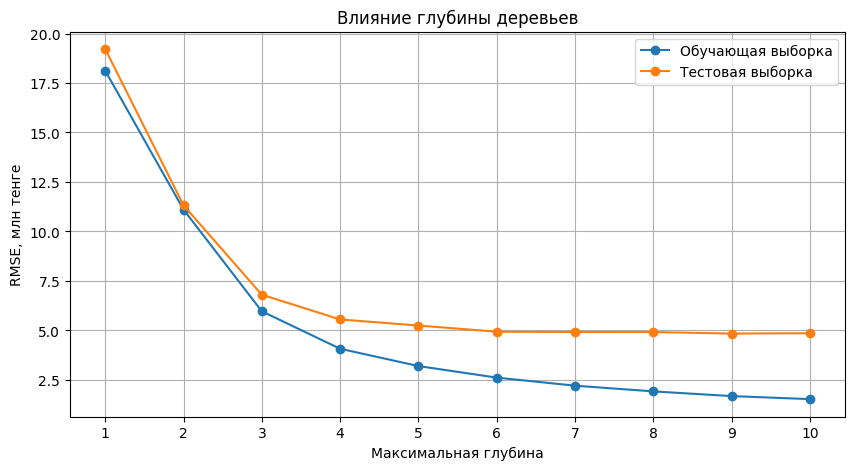

In [50]:
# График влияния глубины деревьев
plt.figure(figsize=(10, 5))
plt.plot(depth_df['Глубина'], depth_df['RMSE на обучении'], marker='o', label='Обучающая выборка')
plt.plot(depth_df['Глубина'], depth_df['RMSE на тесте'], marker='o', label='Тестовая выборка')
plt.xlabel('Максимальная глубина')
plt.ylabel('RMSE, млн тенге')
plt.title('Влияние глубины деревьев')
plt.xticks(range(1, 11))
plt.legend()
plt.grid()
plt.show()

In [51]:
# Лучшая глубина (минимальная RMSE на тесте)
best_depth_result = depth_df.loc[depth_df['RMSE на тесте'].idxmin()]
print(best_depth_result)

Глубина             9.000000
RMSE на обучении    1.673386
RMSE на тесте       4.833265
MAE на тесте        2.873358
R2 на тесте         0.977465
Name: 8, dtype: float64


**Выводы по глубине:**

Лучший результат на тесте при глубине 9 (RMSE = 4,81 млн, R² = 0,978), но уже с глубины 7 качество практически не меняется (RMSE 4,8–4,9). На обучающей выборке ошибка продолжает падать (с 18,1 до 1,5 млн), а на тесте почти нет, то есть дальнейшее увеличение глубины даёт только запоминание обучающих данных. При глубине 1–3 модель слишком простая (недообучение).

In [52]:
# Обучение итогового Random Forest с лучшими параметрами
rf_best_depth = int(best_depth_result['Глубина'])
rf_best_n = int(estimators_df.loc[estimators_df['RMSE'].idxmin(), 'Количество деревьев'])

final_forest = RandomForestRegressor(
    n_estimators=rf_best_n,
    max_depth=rf_best_depth,
    random_state=42
)
final_forest.fit(X_train, y_train)
forest_predictions = final_forest.predict(X_test)

forest_mae, forest_rmse, forest_r2 = evaluate(y_test, forest_predictions)
print('Количество деревьев:', rf_best_n)
print('Оптимальная глубина:', rf_best_depth)
print(f'MAE  = {forest_mae:.2f} млн тенге')
print(f'RMSE = {forest_rmse:.2f} млн тенге')
print(f'R2   = {forest_r2:.3f}')

Количество деревьев: 200
Оптимальная глубина: 9
MAE  = 2.89 млн тенге
RMSE = 4.83 млн тенге
R2   = 0.978


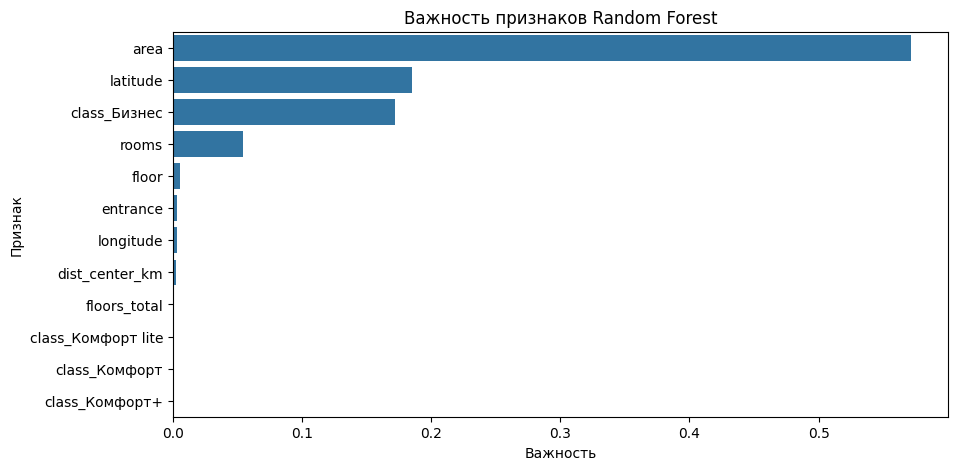

In [53]:
# Важность признаков Random Forest
feature_importance_rf = pd.DataFrame({
    'Признак': X.columns,
    'Важность': final_forest.feature_importances_
}).sort_values(by='Важность', ascending=False)

feature_importance_rf.round(4)

# График важности признаков
plt.figure(figsize=(10, 5))
sns.barplot(data=feature_importance_rf, x='Важность', y='Признак')
plt.title('Важность признаков Random Forest')
plt.show()

1. **Какой признак оказался наиболее важным?**
Ответ: area (площадь), важность 0,57. Затем идут class_Бизнес (0,18) и latitude (0,17).

2. **Какой признак оказался наименее важным?**
Ответ: class_Комфорт+ (важность 0,0001), также почти не используются class_Комфорт, class_Комфорт lite и floors_total.

3. **Совпадает ли результат с деревом решений?**
Ответ: частично. Площадь самый важный признак у обеих моделей (у дерева 0,75, у леса 0,57). Но у дерева вторым стала latitude (0,23), а class_Бизнес и rooms почти не использовались. Лес распределяет важность между признаками более равномерно: так как каждое дерево видит случайный набор признаков, коррелирующие признаки (класс «Бизнес», широта, комнаты) делят влияние между собой.

4. **Можно ли удалить признаки с низкой важностью без дополнительной проверки?**
Ответ: нет. Нужно переобучить модель без них и проверить, не ухудшились ли метрики. Признак может быть маловажным лишь потому, что его информацию уже несёт другой, коррелирующий с ним признак. Если важность делится между такими признаками, она может занижаться.

5. **Доказывает ли важность признака причинную связь?**
Ответ: нет. Важность показывает, насколько часто и эффективно признак использовался для разделения данных, но не то, что он вызывает изменение цены. Например, класс «Бизнес» и широта связаны с одним и тем же ЖК, поэтому влияние одного нельзя отделить от другого.

# K-means

In [54]:
# Импорт для кластеризации
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

Для кластеризации берём 6 числовых признаков: цену, площадь, комнаты, этаж, этажность дома и расстояние до центра. Не берём:

apt_number, complex, source: идентификаторы и текст;

latitude, longitude: дублируют расстояние до центра;

entrance: номер подъезда не описывает свойства квартиры;

class: категориальный признак.

In [55]:
# Выбор признаков для кластеризации
cluster_features = ['price_m', 'area', 'rooms', 'floor', 'floors_total', 'dist_center_km']
df_cluster = df[cluster_features].copy()
print('Размер данных:', df_cluster.shape)
df_cluster.head()

Размер данных: (623, 6)


,price_m,area,rooms,floor,floors_total,dist_center_km
0,72.71271,114.87,4,2,6,11.13
1,42.06400,52.58,3,3,6,11.13
2,44.41380,56.22,3,4,6,11.13
3,42.06400,52.58,3,5,6,11.13
4,23.80888,28.72,1,6,6,11.13


In [56]:
# Типы, статистика, пропуски, дубликаты
df_cluster.info()
print(df_cluster.describe().round(2))
print('Пропусков:', df_cluster.isnull().sum().sum())
print('Количество дубликатов:', df_cluster.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
Index: 623 entries, 0 to 664
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   price_m         623 non-null    float64
 1   area            623 non-null    float64
 2   rooms           623 non-null    int64  
 3   floor           623 non-null    int64  
 4   floors_total    623 non-null    int64  
 5   dist_center_km  623 non-null    float64
dtypes: float64(3), int64(3)
memory usage: 34.1 KB
       price_m    area   rooms   floor  floors_total  dist_center_km
count   623.00  623.00  623.00  623.00        623.00          623.00
mean     63.49   74.68    2.56    5.13          8.68            8.79
std      31.95   28.06    0.98    2.55          2.04            3.48
min      23.81   28.72    1.00    1.00          6.00            4.09
25%      42.33   47.35    2.00    3.00          6.00            6.36
50%      54.47   71.15    3.00    5.00          9.00           11.13
75%    

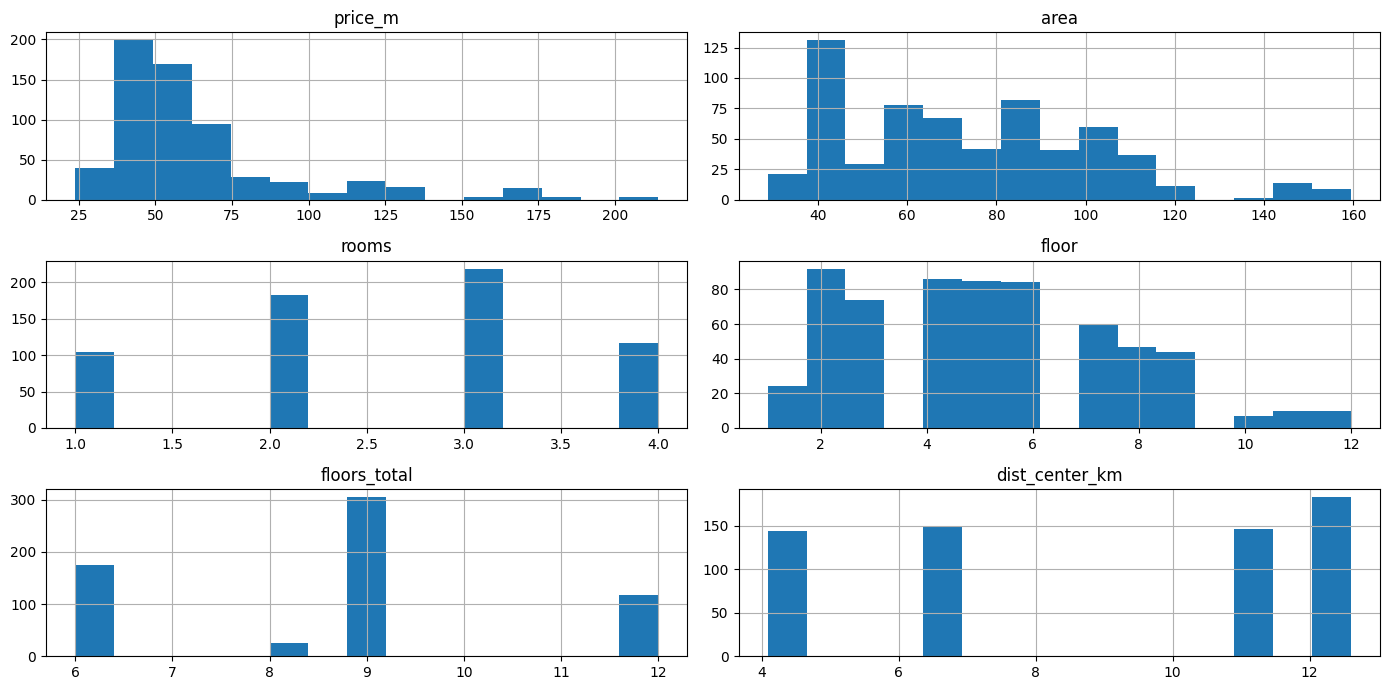

In [57]:
# Распределение признаков
df_cluster.hist(figsize=(14, 7), bins=15)
plt.tight_layout()
plt.show()

1. **Сколько клиентов (объектов) содержится в датасете?**
Ответ: 623 квартиры.

2. **Сколько признаков описывает каждый объект?**
Ответ: 6 признаков: цена, площадь, количество комнат, этаж, этажность дома, расстояние до центра.

3. **Есть ли в данных целевая переменная?**
Ответ: нет. В кластеризации мы не прогнозируем цену, а используем её как одну из характеристик квартиры, чтобы найти группы похожих квартир.

4. **Почему для кластеризации не требуется столбец y?**
Ответ: K-means ищет группы по сходству признаков (расстоянию между объектами) и не сравнивает результат с правильными ответами, поэтому y не нужен.

**Вывод по исследованию данных:**
Признаки числовые. Пропусков нет. Совпадающих строк по этим 6 признакам 46: это разные квартиры с одинаковыми параметрами, поэтому их не удаляем. Диапазоны сильно различаются: цена 23,8–214,1 млн, площадь 28,7–159,5 м², комнаты 1–4, этаж 1–12, этажность 6–12, расстояние до центра 4,1–12,6 км. Масштабирование необходимо.

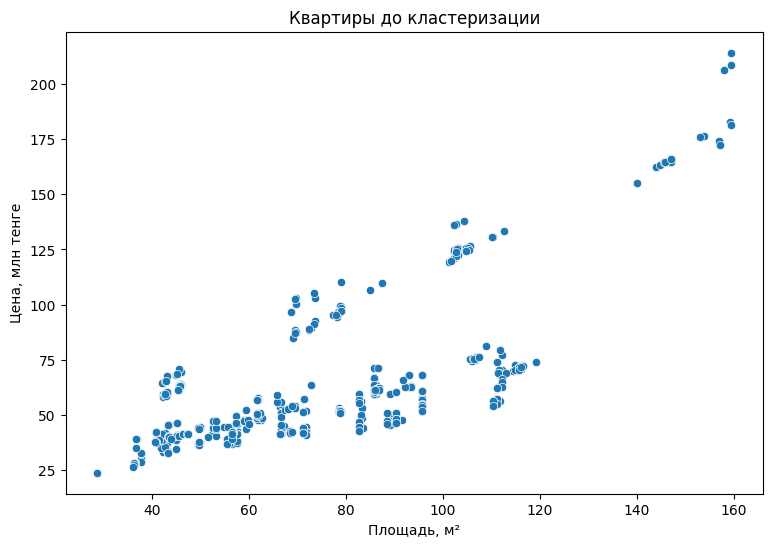

In [58]:
# Объекты до кластеризации
plt.figure(figsize=(9, 6))
sns.scatterplot(data=df_cluster, x='area', y='price_m')
plt.title('Квартиры до кластеризации')
plt.xlabel('Площадь, м²')
plt.ylabel('Цена, млн тенге')
plt.show()

1. **Можно ли визуально заметить группы объектов?**
Ответ: частично. Видно, что цена растёт с площадью, и отдельно выделяется группа дорогих крупных квартир (выше 100 млн). Но чёткие границы между остальными группами не видны, точки образуют непрерывное облако.

2. **Какие признаки используются на графике?**
Ответ: площадь (по оси X) и цена (по оси Y).

3. **Почему по одному графику нельзя точно определить количество кластеров?**
Ответ: график показывает только 2 из 6 признаков, а группы могут отличаться по остальным (этаж, расстояние до центра, этажность). Кроме того, граница между группами субъективна и зависит от взгляда человека.

In [59]:
# Масштабирование признаков для K-means
cluster_scaler = StandardScaler()
X_cl_scaled = cluster_scaler.fit_transform(df_cluster)
X_cl_scaled_df = pd.DataFrame(X_cl_scaled, columns=df_cluster.columns)
X_cl_scaled_df.head()

,price_m,area,rooms,floor,floors_total,dist_center_km
0,0.288846,1.433389,1.472686,-1.225517,-1.313952,0.674528
1,-0.671112,-0.788226,0.449851,-0.833779,-1.313952,0.674528
2,-0.597513,-0.658403,0.449851,-0.442041,-1.313952,0.674528
3,-0.671112,-0.788226,0.449851,-0.050303,-1.313952,0.674528
4,-1.242886,-1.639209,-1.595820,0.341434,-1.313952,0.674528


In [60]:
# Проверка средних значений и размера
print(X_cl_scaled_df.mean().round(2))
print('Строк до и после:', df_cluster.shape[0], X_cl_scaled_df.shape[0])

price_m           0.0
area             -0.0
rooms             0.0
floor             0.0
floors_total      0.0
dist_center_km   -0.0
dtype: float64
Строк до и после: 623 623


1. **Почему масштабирование важно для K-means?**
Ответ: K-means считает расстояния между объектами. Признаки с большими числами (цена до 214, площадь до 159) перевешивали бы признаки с малыми числами (комнаты 1–4), и кластеры строились бы почти только по цене и площади.

2. **Что может произойти без масштабирования?**
Ответ: комнаты, этажи и расстояние до центра почти не влияли бы на результат, а кластеры отражали бы только цену и площадь.

3. **Изменилось ли количество строк после преобразования?**
Ответ: нет, осталось 623 строки. После масштабирования у каждого признака среднее равно 0, а стандартное отклонение 1.

4. **Нужно ли разделять данные на обучающую и тестовую выборки в этой учебной задаче?**
Ответ: нет. Кластеризация это обучение без учителя: правильных ответов нет, поэтому качество на тесте считать не с чем. Мы просто группируем все имеющиеся объекты.

In [61]:
# K-means с 4 кластерами
kmeans_4 = KMeans(n_clusters=4, random_state=42, n_init=10)
clusters_4 = kmeans_4.fit_predict(X_cl_scaled)

df_cluster['Кластер'] = clusters_4
df_cluster.head(10)

,price_m,area,rooms,floor,floors_total,dist_center_km,Кластер
0,72.71271,114.87,4,2,6,11.13,0
1,42.06400,52.58,3,3,6,11.13,3
2,44.41380,56.22,3,4,6,11.13,3
3,42.06400,52.58,3,5,6,11.13,3
4,23.80888,28.72,1,6,6,11.13,3
5,61.08624,86.28,3,2,6,11.13,3
6,52.33550,78.70,3,2,6,11.13,3
7,52.17590,78.46,3,3,6,11.13,3
8,66.95520,85.84,3,4,6,11.13,3
9,46.11500,57.50,2,5,6,11.13,3


In [62]:
# Количество объектов в каждом кластере
df_cluster['Кластер'].value_counts().sort_index()

,count
Кластер,
0,116
1,204
2,161
3,142


1. **Сколько кластеров было создано?**
Ответ: 4 кластера (номера от 0 до 3), в них 116, 204, 161 и 142 квартиры.

2. **Что означает номер в столбце Кластер?**
Ответ: номер группы, к которой алгоритм отнёс квартиру. Это просто метка.

3. **Является ли кластер №0 лучше кластера №1?**
Ответ: нет, номера не означают качество. Они назначаются случайно в начале работы алгоритма.

4. **Почему номера кластеров не являются оценками?**
Ответ: номер только отличает одну группу от другой. Он не показывает ни порядок, ни ценность группы. При другом random_state номера могут поменяться местами.

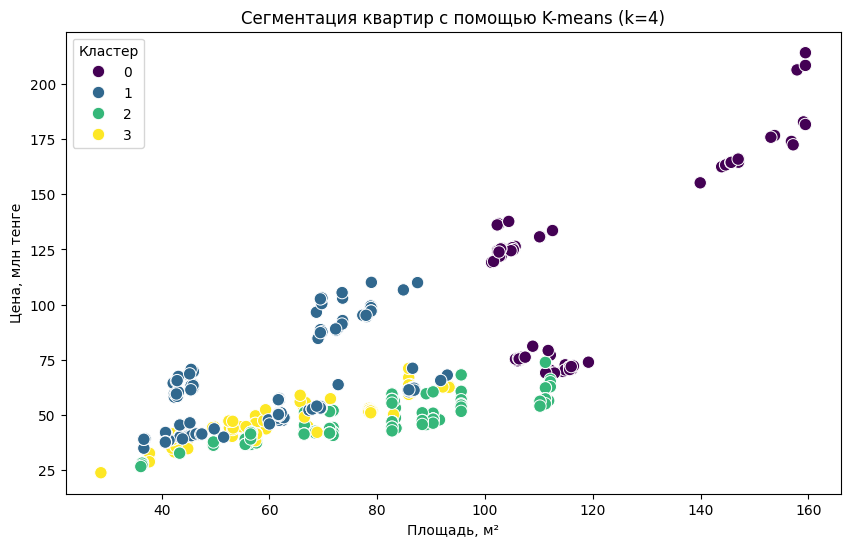

In [63]:
# Кластеры (k=4) на графике площадь и цена
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df_cluster, x='area', y='price_m', hue='Кластер', palette='viridis', s=80)
plt.title('Сегментация квартир с помощью K-means (k=4)')
plt.xlabel('Площадь, м²')
plt.ylabel('Цена, млн тенге')
plt.legend(title='Кластер')
plt.show()

1. **Хорошо ли визуально разделены кластеры?**
Ответ: не очень. Кластер 0 (крупные дорогие квартиры) виден хорошо, а остальные пересекаются, особенно по средним площадям и ценам.

2. **Какие группы объектов можно заметить?**
Ответ: кластер 0 — крупные и дорогие квартиры (в среднем 116,6 м², 111,9 млн); кластер 1 — небольшие квартиры ближе к центру (58,2 м², 60,6 млн, 5,1 км до центра); кластер 2 — квартиры в высоких домах (11 этажей) на окраине (76,3 м², 47,2 млн); кластер 3 — квартиры в низких домах (6,4 этажа) на окраине (62,4 м², 46,7 млн).

3. **Есть ли объекты, находящиеся между кластерами?**
Ответ: да, много. На границах кластеров 1, 2 и 3 точки перемешаны.

4. **Можно ли полностью оценить три и более признака на двумерном графике?**
Ответ: нет. График показывает только площадь и цену, а кластеры построены по 6 признакам. Поэтому разделение по этажу, этажности и расстоянию до центра на нём не видно.

In [64]:
# Метод локтя: k от 1 до 10
inertia_values = []
k_values = range(1, 11)

for k in k_values:
    model_k = KMeans(n_clusters=k, random_state=42, n_init=10)
    model_k.fit(X_cl_scaled)
    inertia_values.append(model_k.inertia_)

elbow_df = pd.DataFrame({
    'Количество кластеров': list(k_values),
    'Inertia': inertia_values
})
elbow_df.round(1)

,Количество кластеров,Inertia
0,1,3738.0
1,2,2748.8
2,3,2099.3
3,4,1671.5
4,5,1457.8
5,6,1265.1
6,7,1079.9
7,8,963.9
8,9,872.0
9,10,776.2


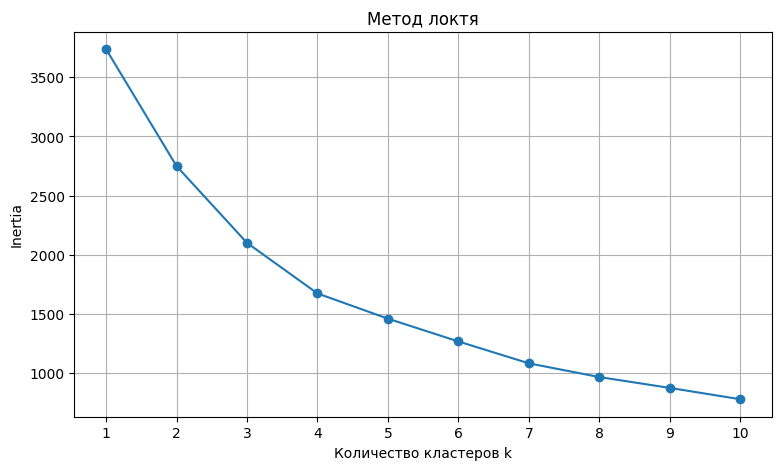

In [65]:
# График метода локтя
plt.figure(figsize=(9, 5))
plt.plot(list(k_values), inertia_values, marker='o')
plt.xlabel('Количество кластеров k')
plt.ylabel('Inertia')
plt.title('Метод локтя')
plt.xticks(list(k_values))
plt.grid()
plt.show()

1. Как изменяется Inertia при увеличении числа кластеров?
Ответ: постоянно уменьшается: с 3738 при k=1 до 776 при k=10. Чем больше кластеров, тем ближе объекты к центрам.

2. В какой точке график начинает снижаться медленнее?
Ответ: после k = 4. До этого каждый новый кластер снижает inertia на 650–990, при k=5 уже на 214, а дальше примерно на 190.

3. Какое количество кластеров показывает метод локтя?
Ответ: примерно 4–5. Чёткого «локтя» нет, график снижается плавно, поэтому метод даёт только ориентир.

4. Почему нельзя просто выбрать максимальное количество кластеров?
Ответ: inertia всегда падает с ростом k. При k = числу объектов она равна 0, но такие кластеры бесполезны: группы получаются слишком мелкими, их нельзя интерпретировать и использовать.

In [66]:
# Silhouette Score для k от 2 до 10
silhouette_results = []

for k in range(2, 11):
    model_s = KMeans(n_clusters=k, random_state=42, n_init=10)
    cluster_labels = model_s.fit_predict(X_cl_scaled)
    score = silhouette_score(X_cl_scaled, cluster_labels)
    silhouette_results.append({'Количество кластеров': k, 'Silhouette Score': score})

silhouette_df = pd.DataFrame(silhouette_results)
silhouette_df.round(3)

,Количество кластеров,Silhouette Score
0,2,0.240
1,3,0.303
2,4,0.325
3,5,0.309
4,6,0.323
5,7,0.339
6,8,0.359
7,9,0.371
8,10,0.369


In [67]:
# Лучший результат по Silhouette Score
best_result_cl = silhouette_df.loc[silhouette_df['Silhouette Score'].idxmax()]
print(best_result_cl)

Количество кластеров    9.000000
Silhouette Score        0.370594
Name: 7, dtype: float64


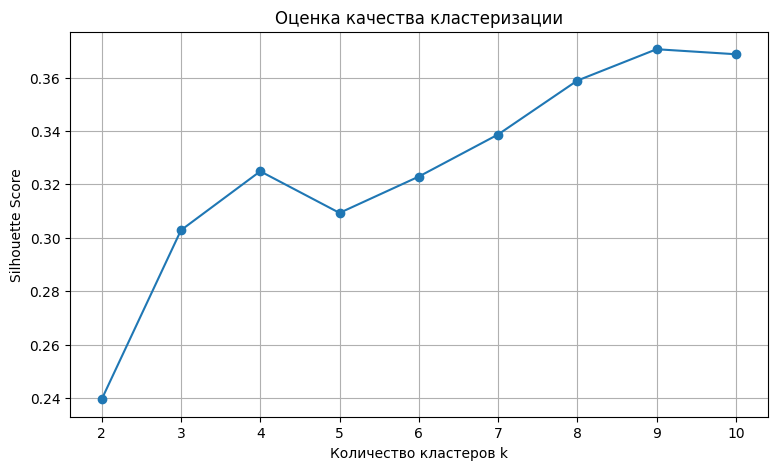

In [68]:
# График Silhouette Score
plt.figure(figsize=(9, 5))
plt.plot(silhouette_df['Количество кластеров'], silhouette_df['Silhouette Score'], marker='o')
plt.xlabel('Количество кластеров k')
plt.ylabel('Silhouette Score')
plt.title('Оценка качества кластеризации')
plt.xticks(range(2, 11))
plt.grid()
plt.show()

1. При каком k получен максимальный Silhouette Score?
Ответ: при k = 9: 0,371.

2. Совпадает ли результат с методом локтя?
Ответ: нет. Локоть указывал на 4–5 кластеров, а максимум Silhouette при 9. Это нормально: методы смотрят на разное, и точного ответа ни один из них не даёт. При этом значения Silhouette для всех k невысокие (0,24–0,37), то есть кластеры в целом перекрываются.

3. Какое количество кластеров вы выбрали?
Ответ: 9 кластеров, потому что у них максимальный Silhouette Score, а 9 совпадает с количеством ЖК (корпусов) в данных, поэтому группы получаются понятными. Более простой вариант k = 4 (Silhouette 0,325, по методу локтя) тоже допустим.

4. Чем Silhouette Score отличается от Accuracy?
Ответ: Accuracy сравнивает прогноз с правильными ответами, а при кластеризации их нет. Silhouette Score не использует ответы, он оценивает только то, насколько объекты близки к своему кластеру и далеки от соседних.

In [69]:
# Выбранное количество кластеров
best_k_cluster = int(best_result_cl['Количество кластеров'])
print('Выбранное количество кластеров:', best_k_cluster)

Выбранное количество кластеров: 9


In [70]:
# Итоговая модель K-means
df_features = df[cluster_features].copy()
X_cl_scaled = cluster_scaler.fit_transform(df_features)

final_kmeans = KMeans(n_clusters=best_k_cluster, random_state=42, n_init=10)
final_clusters = final_kmeans.fit_predict(X_cl_scaled)

df_final = df_features.copy()
df_final['Кластер'] = final_clusters
df_final.head()

,price_m,area,rooms,floor,floors_total,dist_center_km,Кластер
0,72.71271,114.87,4,2,6,11.13,0
1,42.06400,52.58,3,3,6,11.13,6
2,44.41380,56.22,3,4,6,11.13,6
3,42.06400,52.58,3,5,6,11.13,6
4,23.80888,28.72,1,6,6,11.13,6


In [71]:
# Профиль каждого кластера (средние значения)
cluster_profile = df_final.groupby('Кластер').mean().round(1)
cluster_profile['Количество квартир'] = df_final.groupby('Кластер').size()
cluster_profile

,price_m,area,rooms,floor,floors_total,dist_center_km,Количество квартир
Кластер,,,,,,,
0,61.5,91.8,3.3,3.8,6.0,11.1,75
1,52.7,47.9,1.4,4.9,8.6,5.0,137
2,49.6,87.2,3.3,9.4,11.3,12.6,63
3,36.1,49.8,1.6,5.0,11.2,12.6,51
4,113.4,91.6,2.6,5.6,8.3,6.4,69
5,173.3,150.2,4.0,5.3,8.9,6.4,24
6,40.1,47.8,2.0,3.8,6.0,11.1,71
7,66.9,92.5,3.4,4.8,8.8,4.1,64
8,52.9,84.3,3.3,4.3,10.4,12.6,69


Кластер 0 — Просторные квартиры в низких домах (6 этажей), 61,5 млн

Кластер 1 — Компактные квартиры недалеко от центра, 52,7 млн

Кластер 2 — Просторные квартиры на верхних этажах в высотках на окраине, 49,6 млн

Кластер 3 — Самые доступные небольшие квартиры в высотках на окраине, 36,1 млн

Кластер 4 — Бизнес-класс: большие дорогие квартиры, 113,4 млн

Кластер 5 — Премиум: очень большие
(150 м², 4 комнаты) квартиры бизнес-класса, 173,3 млн

Кластер 6 — Недорогие компактные квартиры в низких домах, 40,1 млн

Кластер 7 — Просторные квартиры ближе всего к центру, 66,9 млн

Кластер 8 — Просторные квартиры на нижних этажах в высотках на окраине, 52,9 млн

1. Какой кластер имеет самую высокую цену?
Ответ: кластер 5 (173,3 млн, диапазон 155–214 млн). Следом кластер 4 (113,4 млн).

2. Какой кластер имеет самую большую площадь?
Ответ: кластер 5: 150,2 м² и 4 комнаты. (В этой задаче вместо «оценки расходов» берём площадь.)

3. В каком кластере находятся квартиры ближе всего к центру?
Ответ: в кластере 7 (4,1 км до центра), затем идёт кластер 1 (5,0 км). (Вместо «самых молодых клиентов».)

4. Какой кластер является самым многочисленным?
Ответ: кластер 1 — 137 квартир (22% всех). Самый малочисленный — кластер 5, 24 квартиры.

5. Какие рекомендации можно предложить для каждого сегмента?
Ответ:
Кластеры 3 и 6 (доступные) — предлагать первичным покупателям и молодым семьям, акцент на ипотеке и рассрочке.
Кластер 1 — молодые пары и инвесторы, акцент на удобном расположении и сдаче в аренду.
Кластеры 0, 2, 8 (просторные в низких домах и на окраине) — семьи с детьми, акцент на площади и тихом районе.
Кластер 7 — покупатели, которым важно расположение, цена выше из-за близости к центру.
Кластеры 4 и 5 (бизнес и премиум) — состоятельные покупатели, индивидуальные предложения, показы и персональный менеджер.

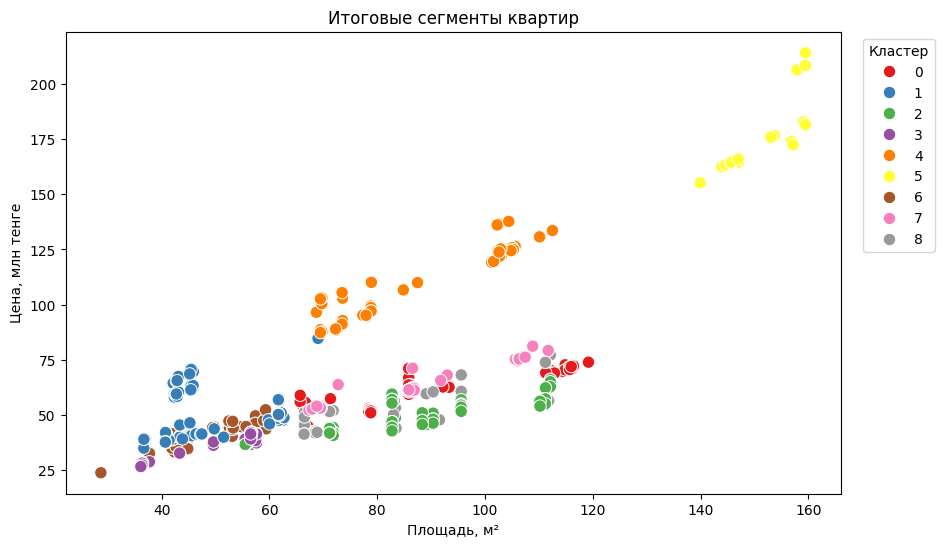

In [72]:
# Итоговые кластеры: площадь и цена
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df_final, x='area', y='price_m', hue='Кластер', palette='Set1', s=80)
plt.title('Итоговые сегменты квартир')
plt.xlabel('Площадь, м²')
plt.ylabel('Цена, млн тенге')
plt.legend(title='Кластер', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.show()

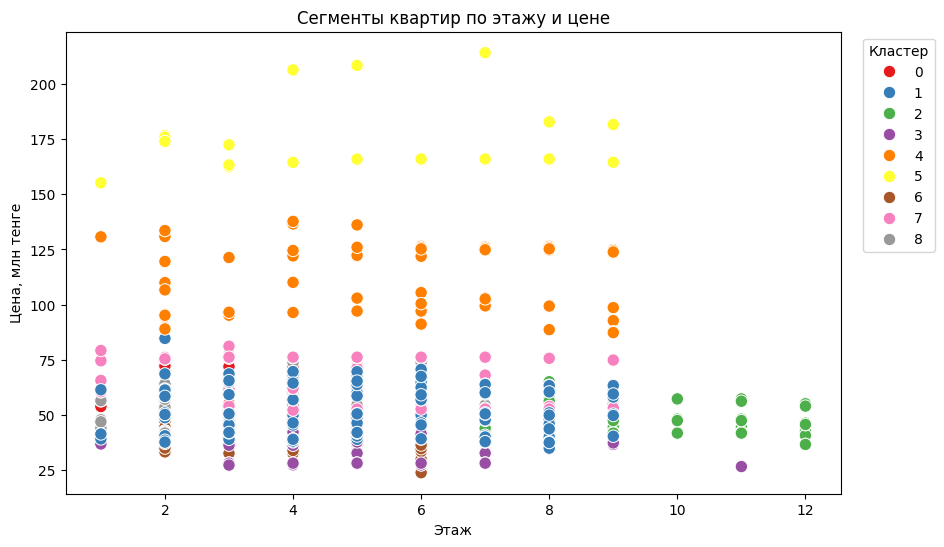

In [73]:
# Дополнительный график: этаж и цена
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df_final, x='floor', y='price_m', hue='Кластер', palette='Set1', s=80)
plt.title('Сегменты квартир по этажу и цене')
plt.xlabel('Этаж')
plt.ylabel('Цена, млн тенге')
plt.legend(title='Кластер', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.show()

1. Чем классификация отличается от кластеризации?
Ответ: в классификации есть целевая переменная y и правильные ответы, модель учится предсказывать класс. В кластеризации ответов нет, алгоритм сам находит группы похожих объектов.

2. Почему для K-means не рассчитывается Accuracy?
Ответ: Accuracy сравнивает прогноз с правильным классом, а для кластеров правильных ответов нет. Вместо неё используют Inertia и Silhouette Score.

3. Может ли K-means самостоятельно объяснить смысл кластеров?
Ответ: нет. Он только присваивает номера. Смысл группы (например, «премиум-квартиры») определяется по средним значениям признаков.

4. Кто должен интерпретировать полученные группы?
Ответ: человек, специалист по предметной области (аналитик, риелтор, маркетолог). Он даёт кластерам названия и решает, как использовать сегменты.

K-means применён к датасету проекта "Прогнозирование стоимости квартир в Алматы" как дополнительный анализ. Признаки: цена, площадь, комнаты, этаж, этажность, расстояние до центра (идентификаторы, координаты и текстовые столбцы удалены). Выполнено масштабирование StandardScaler, проверены k от 2 до 10, построены метод локтя и Silhouette Score. Выбрано 9 кластеров (Silhouette 0,371), составлены профили и названия сегментов. Применение: сегментация предложения для маркетинга и ценообразования застройщика.

# Pipeline, кросс-валидация, GridSearchCV

In [74]:
# Импорт для Pipeline и GridSearchCV
from sklearn.model_selection import cross_val_score, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsRegressor

In [75]:
# Проверка данных и размеров выборок
print('Количество объектов:', X.shape[0])
print('Количество признаков:', X.shape[1])
print('Количество пропусков:', X.isnull().sum().sum())
print('X_train:', X_train.shape)
print('X_test:', X_test.shape)

Количество объектов: 623
Количество признаков: 12
Количество пропусков: 0
X_train: (498, 12)
X_test: (125, 12)


1. Сколько объектов содержит датасет?
Ответ: 623 квартиры: 498 в обучающей и 125 в тестовой выборке.

2. Сколько признаков получает модель?
Ответ: 12 признаков.

3. Какую задачу необходимо решить?
Ответ: регрессию: прогноз цены квартиры price_m (млн тенге).

4. Есть ли в данных пропуски?
Ответ: нет. Пропуски в price (42 забронированные квартиры) были удалены при очистке.

In [76]:
# Базовый Pipeline: масштабирование + KNN (k=5)
baseline_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('model', KNeighborsRegressor(n_neighbors=5))
])
baseline_pipeline.fit(X_train, y_train)
baseline_predictions = baseline_pipeline.predict(X_test)

base_mae, base_rmse, base_r2 = evaluate(y_test, baseline_predictions)
print(f'Базовая модель: MAE={base_mae:.3f}, RMSE={base_rmse:.3f}, R2={base_r2:.3f}')

Базовая модель: MAE=3.742, RMSE=5.283, R2=0.973


1. Какие два этапа входят в Pipeline?
Ответ: scaler (StandardScaler, масштабирование) и model (KNeighborsRegressor, прогноз цены).

2. На каких данных обучается StandardScaler?
Ответ: только на обучающих данных (X_train). К тестовым данным применяется уже обученное масштабирование (transform).

3. Почему масштабирование включено внутрь Pipeline?
Ответ: чтобы масштабирование автоматически обучалось только на обучающей части (в том числе внутри каждого шага кросс-валидации), и чтобы не было утечки данных. Кроме того, все этапы хранятся вместе и не нужно писать код повторно.

4. Какое качество получено?
Ответ: MAE = 3,742 млн, RMSE = 5,283 млн, R² = 0,973.

In [77]:
# 5-кратная кросс-валидация: MAE, RMSE, R2
cv_mae = -cross_val_score(baseline_pipeline, X_train, y_train, cv=5, scoring='neg_mean_absolute_error')
cv_rmse = -cross_val_score(baseline_pipeline, X_train, y_train, cv=5, scoring='neg_root_mean_squared_error')
cv_r2 = cross_val_score(baseline_pipeline, X_train, y_train, cv=5, scoring='r2')

print('RMSE по запускам:', cv_rmse.round(3))
print('Средняя MAE:', cv_mae.mean().round(3), '| std:', cv_mae.std().round(3))
print('Средняя RMSE:', cv_rmse.mean().round(3), '| std:', cv_rmse.std().round(3))
print('Средний R2:', cv_r2.mean().round(3), '| std:', cv_r2.std().round(3))

RMSE по запускам: [6.273 4.643 5.185 5.24  6.744]
Средняя MAE: 3.818 | std: 0.326
Средняя RMSE: 5.617 | std: 0.772
Средний R2: 0.967 | std: 0.009


In [78]:
# Таблица результатов кросс-валидации
cv_results_df = pd.DataFrame({
    'Запуск': range(1, 6),
    'MAE': cv_mae,
    'RMSE': cv_rmse,
    'R2': cv_r2
})
cv_results_df.round(3)

,Запуск,MAE,RMSE,R2
0,1,4.078,6.273,0.961
1,2,3.390,4.643,0.982
2,3,3.607,5.185,0.959
3,4,3.720,5.240,0.974
4,5,4.294,6.744,0.960


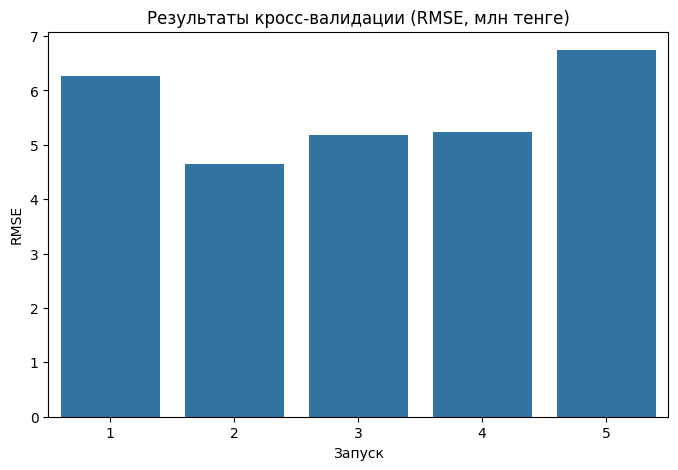

In [79]:
# Диаграмма кросс-валидации (RMSE)
plt.figure(figsize=(8, 5))
sns.barplot(data=cv_results_df, x='Запуск', y='RMSE')
plt.title('Результаты кросс-валидации (RMSE, млн тенге)')
plt.show()

1. Сколько раз обучалась модель?
Ответ: 5 раз (cv=5), каждый раз на 4 частях обучающей выборки, а проверка на оставшейся.

2. Одинаковые ли результаты получены?
Ответ: нет. RMSE менялась от 4,64 до 6,74 млн в зависимости от того, какие квартиры попали в проверочную часть.

3. Какова средняя ошибка?
Ответ: средняя MAE = 3,82 млн, RMSE = 5,62 млн, R² = 0,967.

4. Что показывает стандартное отклонение?
Ответ: разброс результатов между запусками. Для RMSE оно равно 0,77 млн, то есть результат заметно зависит от разбиения. Чем оно меньше, тем стабильнее модель.

5. Чем кросс-валидация надёжнее одной проверки?
Ответ: оценка считается по 5 разным частям данных и усредняется, поэтому она меньше зависит от случайного попадания объектов в тестовую выборку.

# Pipeline, кросс-валидация, GridSearchCV

In [80]:
# Pipeline для поиска и сетка параметров
search_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('model', KNeighborsRegressor())
])

parameter_grid = {
    'model__n_neighbors': [3, 5, 7, 9, 11, 13, 15],
    'model__weights': ['uniform', 'distance'],
    'model__p': [1, 2]
}

number_of_combinations = (
    len(parameter_grid['model__n_neighbors']) *
    len(parameter_grid['model__weights']) *
    len(parameter_grid['model__p'])
)
print('Количество комбинаций:', number_of_combinations)

Количество комбинаций: 28


In [81]:
# GridSearchCV: качество оцениваем по RMSE
grid_search = GridSearchCV(
    estimator=search_pipeline,
    param_grid=parameter_grid,
    cv=5,
    scoring='neg_root_mean_squared_error',
    n_jobs=-1,
    return_train_score=True
)
grid_search.fit(X_train, y_train)

GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('scaler', StandardScaler()),
                                       ('model', KNeighborsRegressor())]),
             n_jobs=-1,
             param_grid={'model__n_neighbors': [3, 5, 7, 9, 11, 13, 15],
                         'model__p': [1, 2],
                         'model__weights': ['uniform', 'distance']},
             return_train_score=True, scoring='neg_root_mean_squared_error')

In [82]:
# Лучшие параметры и результат кросс-валидации
print('Лучшие параметры:', grid_search.best_params_)
print('Лучшая средняя RMSE:', round(-grid_search.best_score_, 3))

knn_best_model = grid_search.best_estimator_
knn_best_model

Лучшие параметры: {'model__n_neighbors': 3, 'model__p': 1, 'model__weights': 'distance'}
Лучшая средняя RMSE: 3.899


Pipeline(steps=[('scaler', StandardScaler()),
                ('model',
                 KNeighborsRegressor(n_neighbors=3, p=1, weights='distance'))])

1. Какое значение n_neighbors выбрано?
Ответ: 3 соседа.

2. Какой тип весов оказался лучшим?
Ответ: distance (ближайшие соседи влияют сильнее).

3. Какое расстояние выбрано?
Ответ: манхэттенское (p = 1).

4. Какую среднюю ошибку показала лучшая модель?
Ответ: средняя RMSE при кросс-валидации = 3,90 млн тенге (у базовой модели 5,62 млн).

In [83]:
# Таблица результатов GridSearchCV (знак ошибки возвращаем в положительный)
grid_results = pd.DataFrame(grid_search.cv_results_)

grid_results_short = grid_results[[
    'param_model__n_neighbors', 'param_model__weights', 'param_model__p',
    'mean_train_score', 'mean_test_score', 'std_test_score', 'rank_test_score'
]].copy()

grid_results_short['mean_train_score'] = -grid_results_short['mean_train_score']
grid_results_short['mean_test_score'] = -grid_results_short['mean_test_score']
grid_results_short = grid_results_short.sort_values(by='rank_test_score')

grid_results_short = grid_results_short.rename(columns={
    'param_model__n_neighbors': 'Количество соседей',
    'param_model__weights': 'Веса',
    'param_model__p': 'Тип расстояния',
    'mean_train_score': 'RMSE на обучении',
    'mean_test_score': 'Средняя RMSE (CV)',
    'std_test_score': 'Стандартное отклонение',
    'rank_test_score': 'Место'
})
grid_results_short.head(10).round(3)

,Количество соседей,Веса,Тип расстояния,RMSE на обучении,Средняя RMSE (CV),Стандартное отклонение,Место
1,3,distance,1,0.114,3.899,0.329,1
5,5,distance,1,0.114,4.089,0.463,2
0,3,uniform,1,2.993,4.119,0.278,3
9,7,distance,1,0.114,4.268,0.497,4
13,9,distance,1,0.114,4.370,0.540,5
17,11,distance,1,0.114,4.518,0.531,6
3,3,distance,2,0.114,4.559,0.582,7
4,5,uniform,1,3.704,4.583,0.488,8
21,13,distance,1,0.114,4.609,0.561,9
25,15,distance,1,0.114,4.686,0.600,10


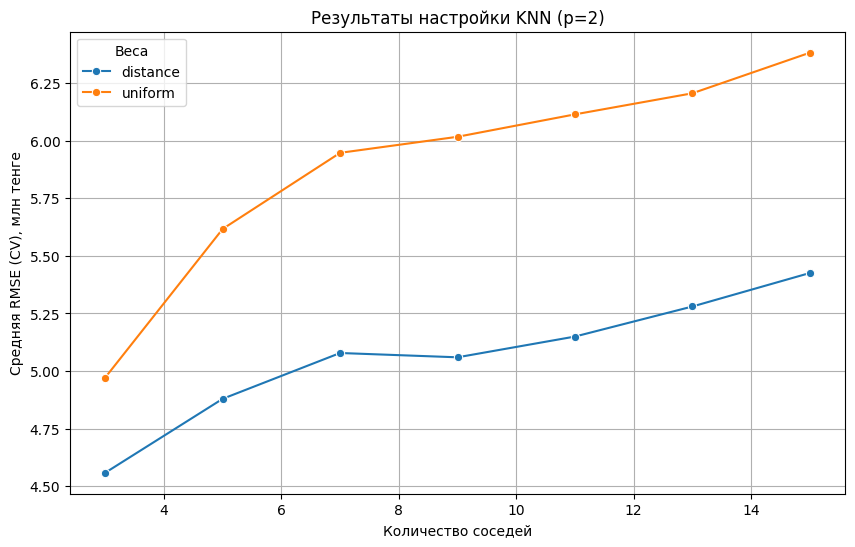

In [84]:
# График: евклидово расстояние (p=2)
plot_data = grid_results_short[grid_results_short['Тип расстояния'] == 2].copy()
plot_data['Количество соседей'] = plot_data['Количество соседей'].astype(int)

plt.figure(figsize=(10, 6))
sns.lineplot(data=plot_data, x='Количество соседей', y='Средняя RMSE (CV)', hue='Веса', marker='o')
plt.title('Результаты настройки KNN (p=2)')
plt.xlabel('Количество соседей')
plt.ylabel('Средняя RMSE (CV), млн тенге')
plt.grid()
plt.show()

1. Как значение k влияет на результат?
Ответ: с ростом k ошибка растёт. Например, при p = 2 и весах distance RMSE увеличивается с 4,56 (k=3) до 5,43 (k=15). Чем больше соседей, тем сильнее усредняются разные квартиры.

2. Какие веса показали лучший результат?
Ответ: distance. При k=3 RMSE 4,56 против 4,97 у uniform, а при k=15 5,43 против 6,38.

3. Есть ли большая разница между комбинациями?
Ответ: да, заметная. RMSE от 3,90 млн у лучшей комбинации до 6,38 млн у худшей.

4. Можно ли определить лучший параметр только по графику?
Ответ: нет. На графике только часть комбинаций (p = 2), а лучшая комбинация использует p = 1. Нужно смотреть таблицу, стандартное отклонение и место в рейтинге.

In [85]:
# Оценка лучшей модели на тестовой выборке
grid_predictions = knn_best_model.predict(X_test)
best_mae, best_rmse, best_r2 = evaluate(y_test, grid_predictions)
print(f'Лучшая модель на тесте: MAE={best_mae:.3f}, RMSE={best_rmse:.3f}, R2={best_r2:.3f}')

Лучшая модель на тесте: MAE=3.382, RMSE=5.234, R2=0.974


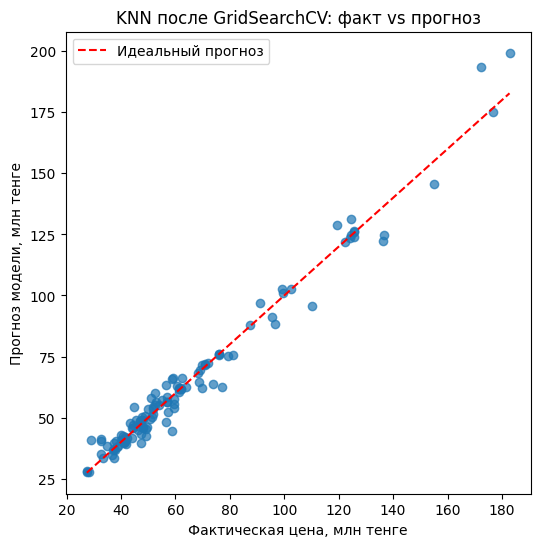

count    1.250000e+02
mean     3.381757e+00
std      4.010268e+00
min      1.421085e-14
25%      5.291028e-01
50%      1.712797e+00
75%      4.027749e+00
max      2.101246e+01
Name: price_m, dtype: float64
Ошибок больше 10 млн: 8
MAE дорогих (топ-10%): 6.58


In [86]:
# График "факт vs прогноз" и ошибки
plt.figure(figsize=(6, 6))
plt.scatter(y_test, grid_predictions, alpha=0.7)
lims = [y_test.min(), y_test.max()]
plt.plot(lims, lims, 'r--', label='Идеальный прогноз')
plt.xlabel('Фактическая цена, млн тенге')
plt.ylabel('Прогноз модели, млн тенге')
plt.title('KNN после GridSearchCV: факт vs прогноз')
plt.legend()
plt.show()

grid_errors = grid_predictions - y_test
print(grid_errors.abs().describe())
print('Ошибок больше 10 млн:', (grid_errors.abs() > 10).sum())
expensive = y_test > y_test.quantile(0.9)
print('MAE дорогих (топ-10%):', round(grid_errors[expensive].abs().mean(), 2))

1. Сколько объектов классифицировано правильно?
Ответ: в регрессии «правильно или нет» не бывает, смотрим на размер ошибки. Для половины тестовых квартир ошибка не больше 1,71 млн (медиана), для четверти меньше 0,53 млн. Ошибок больше 10 млн всего 8 из 125.

2. Какие объекты модель перепутала?
Ответ: хуже всего прогнозируются дорогие квартиры: для топ-10% по цене средняя ошибка 6,58 млн, максимальная ошибка 21,0 млн.

3. Какие объекты определяются лучше всего?
Ответ: квартиры средней и низкой цены, у которых много похожих соседей в обучающей выборке.

4. Есть ли объекты с низким качеством прогноза (аналог низкого Recall)?
Ответ: да, дорогие квартиры бизнес-класса и премиум-сегмента, их в данных мало.

In [87]:
# Сравнение базового KNN и KNN после GridSearchCV
comparison_tuning = pd.DataFrame({
    'Модель': ['Базовый KNN (k=5)', 'KNN после GridSearchCV'],
    'MAE на тесте': [base_mae, best_mae],
    'RMSE на тесте': [base_rmse, best_rmse],
    'R2 на тесте': [base_r2, best_r2]
})
comparison_tuning.round(3)

,Модель,MAE на тесте,RMSE на тесте,R2 на тесте
0,Базовый KNN (k=5),3.742,5.283,0.973
1,KNN после GridSearchCV,3.382,5.234,0.974


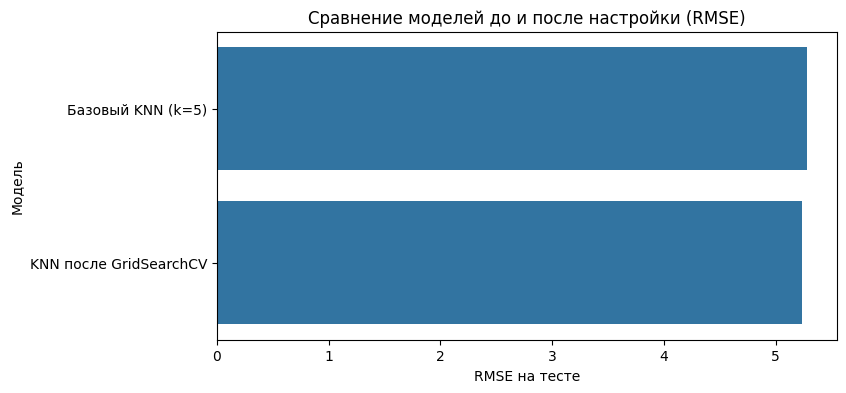

Изменение RMSE: -0.049
Изменение MAE: -0.36


In [88]:
# Диаграмма и изменение метрики
plt.figure(figsize=(8, 4))
sns.barplot(data=comparison_tuning, x='RMSE на тесте', y='Модель')
plt.title('Сравнение моделей до и после настройки (RMSE)')
plt.show()

print('Изменение RMSE:', round(best_rmse - base_rmse, 3))
print('Изменение MAE:', round(best_mae - base_mae, 3))

1. Улучшился ли результат?
Ответ: да, но немного. MAE снизилась с 3,74 до 3,38 млн, RMSE с 5,28 до 5,23 млн, R² вырос с 0,973 до 0,974.

2. Насколько изменилась ошибка?
Ответ: MAE уменьшилась на 0,36 млн (около 10%), RMSE на 0,05 млн (около 1%).

3. Может ли GridSearchCV выбрать модель с таким же результатом?
Ответ: да. Если базовые параметры уже близки к оптимальным, лучшая комбинация может оказаться почти такой же.

4. Означает ли небольшой рост, что настройка была бесполезной?
Ответ: нет. По кросс-валидации настройка дала заметное улучшение: средняя RMSE снизилась с 5,62 до 3,90 млн. На тесте выигрыш меньше, потому что там всего 125 квартир (результат менее стабилен), а лучшая комбинация выбрана именно на CV, поэтому оценка CV оптимистичнее тестовой. Настройка также подтвердила, что k = 5 с равными весами был не лучшим выбором.

5. Почему итоговая проверка проводится на отдельной тестовой выборке?
Ответ: тестовые данные не участвовали ни в обучении, ни в подборе параметров, поэтому показывают, как модель поведёт себя на новых квартирах. Если проверять на данных, по которым выбирались параметры, оценка будет завышена.

In [89]:
# Сравнение качества на обучении и тесте
train_pred = knn_best_model.predict(X_train)
train_mae, train_rmse, train_r2 = evaluate(y_train, train_pred)

print(f'Обучение: MAE={train_mae:.3f}, RMSE={train_rmse:.3f}, R2={train_r2:.5f}')
print(f'Тест:     MAE={best_mae:.3f}, RMSE={best_rmse:.3f}, R2={best_r2:.5f}')
print('Разница RMSE:', round(best_rmse - train_rmse, 3))

Обучение: MAE=0.012, RMSE=0.161, R2=0.99997
Тест:     MAE=3.382, RMSE=5.234, R2=0.97358
Разница RMSE: 5.072


1. Есть ли разница между обучением и тестированием?
Ответ: да, большая. На обучении RMSE = 0,16 млн, R² = 0,99997, а на тесте RMSE = 5,23 млн, R² = 0,974. Разница в RMSE около 5 млн.

2. Можно ли предположить переобучение?
Ответ: да. Модель с 3 соседями и весами distance фактически запоминает обучающие квартиры (каждая сама себе ближайший сосед). Но на тесте результат всё равно высокий (R² 0,974), поэтому переобучение умеренное.

3. Что можно изменить для уменьшения переобучения?
Ответ: увеличить число соседей k, использовать веса uniform, собрать больше данных, проверить модель на кросс-валидации, использовать другую модель (например, Random Forest с ограничением глубины) или сократить число признаков.

In [90]:
# Демонстрация: масштабирование ВСЕЙ обучающей выборки до кросс-валидации (неправильный способ)
X_train_prescaled = StandardScaler().fit_transform(X_train)
leak_rmse = -cross_val_score(
    KNeighborsRegressor(n_neighbors=5), X_train_prescaled, y_train,
    cv=5, scoring='neg_root_mean_squared_error'
).mean()

print('RMSE с утечкой (масштабирование до CV):', round(leak_rmse, 3))
print('RMSE через Pipeline (правильно):', round(cv_rmse.mean(), 3))

RMSE с утечкой (масштабирование до CV): 5.598
RMSE через Pipeline (правильно): 5.617


1. Что называется утечкой данных?
Ответ: ситуация, когда информация из проверочных или тестовых данных попадает в обучение модели или подготовку данных (например, среднее и стандартное отклонение считаются по всему датасету).

2. Почему нельзя заранее масштабировать весь датасет?
Ответ: тогда масштабирование «видит» тестовые объекты. Среднее и стандартное отклонение считаются в том числе по ним, и оценка качества получается нечестной.

3. Как Pipeline помогает избежать этой ошибки?
Ответ: при кросс-валидации Pipeline заново обучает StandardScaler внутри каждого шага только на обучающей части, а к проверочной части применяет уже обученное масштабирование.

4. Может ли утечка искусственно повысить метрики?
Ответ: да. Модель получает косвенную информацию о тестовых данных и показывает результат лучше, чем покажет на реальных новых данных. В нашем случае эффект мал (разница в RMSE 0,02 млн), но так бывает не всегда.

In [91]:
# Pipeline и GridSearchCV для Random Forest
from sklearn.ensemble import RandomForestRegressor

project_pipeline = Pipeline([
    ('model', RandomForestRegressor(random_state=42))
])

project_grid = {
    'model__n_estimators': [50, 100, 200],
    'model__max_depth': [None, 3, 5, 10],
    'model__min_samples_leaf': [1, 2, 4]
}

project_search = GridSearchCV(
    estimator=project_pipeline,
    param_grid=project_grid,
    cv=5,
    scoring='neg_root_mean_squared_error',
    n_jobs=-1
)
project_search.fit(X_train, y_train)

print('Лучшие параметры:', project_search.best_params_)
print('Лучший результат CV (RMSE):', round(-project_search.best_score_, 3))

Лучшие параметры: {'model__max_depth': None, 'model__min_samples_leaf': 1, 'model__n_estimators': 200}
Лучший результат CV (RMSE): 3.288


In [92]:
# Оценка настроенного Random Forest на тесте
rf_tuned = project_search.best_estimator_
rf_t_mae, rf_t_rmse, rf_t_r2 = evaluate(y_test, rf_tuned.predict(X_test))
print(f'Тест: MAE={rf_t_mae:.3f}, RMSE={rf_t_rmse:.3f}, R2={rf_t_r2:.3f}')

Тест: MAE=2.827, RMSE=4.824, R2=0.978


# MLPRegressor — многослойный перцептрон

In [93]:
from sklearn.neural_network import MLPRegressor
from sklearn.model_selection import KFold, cross_val_score
from sklearn.pipeline import make_pipeline

*MLPRegressor*— нейронная сеть для решения задач регрессии.



*KFold* — разделяет обучающую выборку на части для кросс-валидации.



*cross_val_score*— позволяет оценить качество разных архитектур.



*make_pipeline*— объединяет масштабирование и обучение модели.

In [94]:
# Проверяем, что используем уже подготовленные выборки

print('Обучающая выборка:', X_train.shape)
print('Тестовая выборка:', X_test.shape)

print('Размер y_train:', y_train.shape)
print('Размер y_test:', y_test.shape)

print('\nПропуски в обучающих данных:', X_train.isnull().sum().sum())
print('Пропуски в тестовых данных:', X_test.isnull().sum().sum())

Обучающая выборка: (498, 12)
Тестовая выборка: (125, 12)
Размер y_train: (498,)
Размер y_test: (125,)

Пропуски в обучающих данных: 0
Пропуски в тестовых данных: 0


In [95]:
# Базовая архитектура MLP

mlp_pipeline = make_pipeline(
    StandardScaler(),
    MLPRegressor(
        hidden_layer_sizes=(50,),
        activation='relu',
        solver='adam',
        max_iter=1000,
        random_state=42,
        early_stopping=True
    )
)

# Обучение нейронной сети
mlp_pipeline.fit(X_train, y_train)

print('Нейронная сеть успешно обучена!')

Нейронная сеть успешно обучена!


In [96]:
# Прогнозирование на тестовой выборке

mlp_predictions = mlp_pipeline.predict(X_test)

# Расчёт метрик
mlp_mae = mean_absolute_error(y_test, mlp_predictions)
mlp_mse = mean_squared_error(y_test, mlp_predictions)
mlp_rmse = np.sqrt(mlp_mse)
mlp_r2 = r2_score(y_test, mlp_predictions)

print('Результаты MLPRegressor:')
print('MAE:', round(mlp_mae, 3), 'млн ₸')
print('MSE:', round(mlp_mse, 3))
print('RMSE:', round(mlp_rmse, 3), 'млн ₸')
print('R²:', round(mlp_r2, 4))

Результаты MLPRegressor:
MAE: 4.361 млн ₸
MSE: 29.792
RMSE: 5.458 млн ₸
R²: 0.9713


In [97]:
#Сравниваем разные архитектуры нейронной сети
# Сравнение архитектур нейронной сети MLP

architectures = [(20,), (50,), (50, 25)]

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

architecture_results = []

for architecture in architectures:

    model = make_pipeline(
        StandardScaler(),
        MLPRegressor(
            hidden_layer_sizes=architecture,
            activation='relu',
            solver='adam',
            max_iter=1000,
            random_state=42,
            early_stopping=True
        )
    )

    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring='neg_mean_absolute_error',
        n_jobs=-1
    )

    architecture_results.append({
        'Архитектура': str(architecture),
        'MAE средняя': -scores.mean(),
        'Стандартное отклонение': scores.std()
    })

architecture_results = pd.DataFrame(architecture_results)

display(architecture_results.round(3))

,Архитектура,MAE средняя,Стандартное отклонение
0,"(20,)",5.872,0.330
1,"(50,)",4.940,0.481
2,"(50, 25)",3.852,0.405


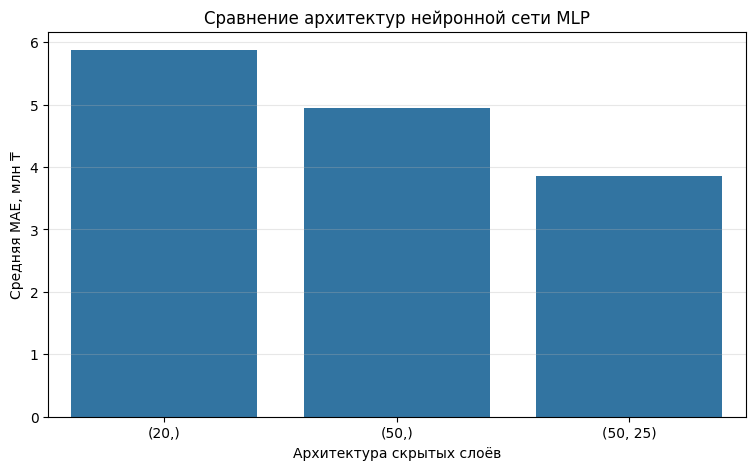

In [98]:
#Строим график сравнения архитектур
plt.figure(figsize=(9, 5))

sns.barplot(
    data=architecture_results,
    x='Архитектура',
    y='MAE средняя'
)

plt.title('Сравнение архитектур нейронной сети MLP')
plt.xlabel('Архитектура скрытых слоёв')
plt.ylabel('Средняя MAE, млн ₸')
plt.grid(axis='y', alpha=0.3)

plt.show()

In [99]:
# Выбираем архитектуру с минимальной MAE
best_index = architecture_results['MAE средняя'].idxmin()

best_architecture = architectures[best_index]

print('Лучшая архитектура:', best_architecture)

# Создаём итоговую модель
mlp_pipeline = make_pipeline(
    StandardScaler(),
    MLPRegressor(
        hidden_layer_sizes=best_architecture,
        activation='relu',
        solver='adam',
        max_iter=1000,
        random_state=42,
        early_stopping=True
    )
)

# Обучаем на общей обучающей выборке
mlp_pipeline.fit(X_train, y_train)

# Прогноз
mlp_predictions = mlp_pipeline.predict(X_test)

# Метрики
mlp_mae, mlp_rmse, mlp_r2 = evaluate(
    y_test,
    mlp_predictions
)

print('\nИтоговые результаты MLP:')
print(f'MAE:  {mlp_mae:.3f} млн ₸')
print(f'RMSE: {mlp_rmse:.3f} млн ₸')
print(f'R²:   {mlp_r2:.4f}')

Лучшая архитектура: (50, 25)

Итоговые результаты MLP:
MAE:  3.547 млн ₸
RMSE: 4.607 млн ₸
R²:   0.9795


In [100]:
trained_mlp = mlp_pipeline.named_steps['mlpregressor']

print('Количество итераций:', trained_mlp.n_iter_)
print('Максимум итераций:', trained_mlp.max_iter)
print('Количество скрытых слоёв:', len(best_architecture))
print('Количество нейронов:', best_architecture)
print('Ранняя остановка:', trained_mlp.early_stopping)

Количество итераций: 302
Максимум итераций: 1000
Количество скрытых слоёв: 2
Количество нейронов: (50, 25)
Ранняя остановка: True


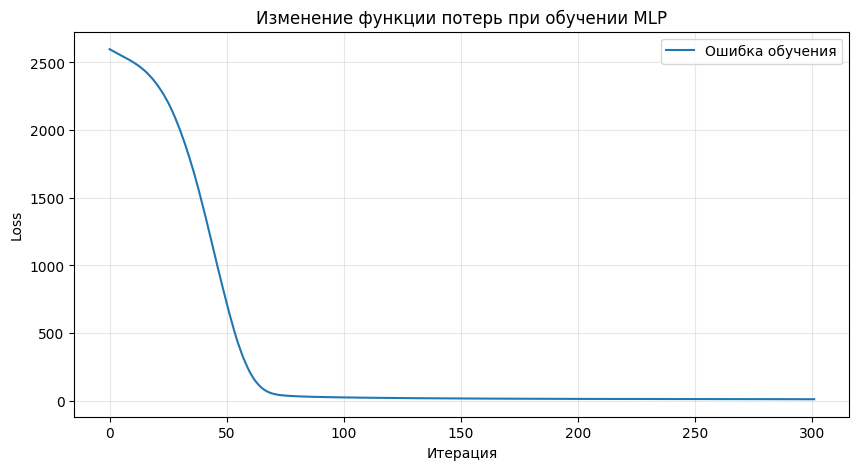

In [101]:
#Построим график функции потерь
plt.figure(figsize=(10, 5))

plt.plot(
    trained_mlp.loss_curve_,
    label='Ошибка обучения'
)

plt.xlabel('Итерация')
plt.ylabel('Loss')
plt.title('Изменение функции потерь при обучении MLP')
plt.legend()
plt.grid(alpha=0.3)

plt.show()

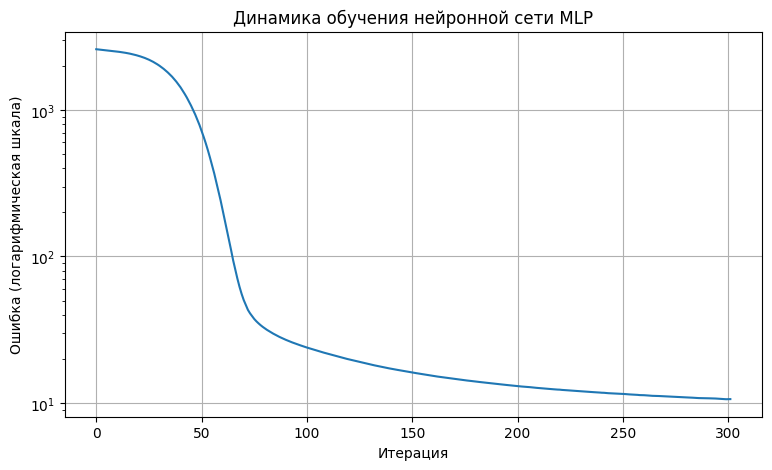

In [102]:
#Дополнительно — логарифмический масштаб
plt.figure(figsize=(9, 5))

plt.plot(trained_mlp.loss_curve_)
plt.yscale('log')

plt.xlabel('Итерация')
plt.ylabel('Ошибка (логарифмическая шкала)')
plt.title('Динамика обучения нейронной сети MLP')
plt.grid()

plt.show()

In [103]:
print(
    'Ошибка в начале обучения:',
    round(trained_mlp.loss_curve_[0], 4)
)

print(
    'Ошибка в конце обучения:',
    round(trained_mlp.loss_curve_[-1], 4)
)

print(
    'Изменение ошибки:',
    round(
        trained_mlp.loss_curve_[0] -
        trained_mlp.loss_curve_[-1], 4
    )
)

Ошибка в начале обучения: 2596.9355
Ошибка в конце обучения: 10.619
Изменение ошибки: 2586.3165



**1. Какую задачу решает нейронная сеть?**

Нейронная сеть MLPRegressor решает задачу регрессии — прогнозирует стоимость квартир в новостройках Алматы на основе их характеристик. Целевой переменной является `price_m`, выраженная в миллионах тенге.

**2. Почему необходимо масштабирование признаков?**

Масштабирование необходимо, поскольку признаки имеют разные единицы измерения и диапазоны значений. StandardScaler преобразует числовые признаки к сопоставимому масштабу, что помогает нейронной сети эффективнее обучаться и быстрее находить оптимальные веса.

**3. Какая архитектура показала лучший результат?**

Лучшая архитектура определяется по минимальному среднему значению MAE при пятиблочной кросс-валидации. В отличие от оценки на одной тестовой выборке, такой подход позволяет учитывать устойчивость модели на разных частях обучающих данных. Указать архитектуру и значение MAE по таблице `architecture_results`.

**4. Всегда ли увеличение количества нейронов улучшает результат?**

Нет. Увеличение количества нейронов и скрытых слоёв не гарантирует повышения точности. Слишком простая сеть может не выявлять сложные зависимости, а чрезмерно сложная — увеличивать время обучения и риск переобучения.

**5. Для чего используется параметр early_stopping?**

Early stopping останавливает обучение, если качество модели на внутренней проверочной части обучающей выборки перестаёт улучшаться. Это помогает избежать избыточного обучения и снизить риск переобучения.

**6. Уменьшается ли ошибка в процессе обучения?**

Изменение ошибки оценивается по графику `loss_curve_`. Если начальное значение выше конечного, функция потерь уменьшилась. Если в конце кривая становится более пологой, это свидетельствует о стабилизации процесса обучения.

**7. Сколько итераций потребовалось для обучения?**

Фактическое количество итераций определяется параметром `trained_mlp.n_iter_`. Максимально допустимое количество итераций установлено равным 1000. Указать результат выполнения соответствующей ячейки.

**8. Какую роль играет random_state?**

Параметр random_state обеспечивает воспроизводимость результатов. При повторном запуске с одинаковыми данными и настройками он позволяет получить сопоставимые результаты обучения.

# Сравнение моделей машинного обучения

*Цель:* сравнить качество различных алгоритмов машинного обучения при прогнозировании стоимости квартир в новостройках Алматы.

В исследовании рассматриваются пять моделей:

*Linear Regression* — линейная регрессия.

*KNN Regressor* — метод ближайших соседей.

*Decision Tree Regressor* — дерево решений.

*Random Forest Regressor* — случайный лес.

*MLPRegressor* — многослойная нейронная сеть.

Все модели обучаются на одной обучающей выборке и проверяются на одной тестовой выборке. Для объективного сравнения используются три метрики: MAE, RMSE и R².

MAE и RMSE измеряются в миллионах тенге. Чем меньше их значения, тем точнее прогноз. Чем ближе R² к единице, тем большую часть вариации стоимости квартир объясняет модель.

In [104]:
# Сравнение пяти алгоритмов машинного обучения

from sklearn.tree import DecisionTreeRegressor
from sklearn.dummy import DummyRegressor

models_15 = {
    'Linear Regression': LinearRegression(),

    'KNN': make_pipeline(
        StandardScaler(),
        KNeighborsRegressor(
            n_neighbors=4
        )
    ),

    'Decision Tree': DecisionTreeRegressor(
        max_depth=8,
        random_state=42
    ),

    'Random Forest': RandomForestRegressor(
        n_estimators=200,
        max_depth=9,
        random_state=42
    ),

    'MLPRegressor': make_pipeline(
        StandardScaler(),
        MLPRegressor(
            hidden_layer_sizes=best_architecture,
            activation='relu',
            solver='adam',
            max_iter=1000,
            random_state=42,
            early_stopping=True
        )
    )
}

# Обучение и прогнозирование
predictions_15 = {}

for name, model in models_15.items():

    model.fit(X_train, y_train)

    predictions_15[name] = model.predict(X_test)

    print(f'{name}: обучение завершено')

print('\nВсе пять моделей успешно обучены.')

Linear Regression: обучение завершено
KNN: обучение завершено
Decision Tree: обучение завершено
Random Forest: обучение завершено
MLPRegressor: обучение завершено

Все пять моделей успешно обучены.


In [105]:
# Расчёт метрик на тестовой выборке

comparison_rows = []

for name, predictions in predictions_15.items():

    mae, rmse, r2 = evaluate(
        y_test,
        predictions
    )

    comparison_rows.append({
        'Модель': name,
        'MAE, млн ₸': mae,
        'RMSE, млн ₸': rmse,
        'R²': r2
    })

models_comparison_15 = pd.DataFrame(
    comparison_rows
)

# Сортировка по RMSE
models_comparison_15 = (
    models_comparison_15
    .sort_values('RMSE, млн ₸')
    .reset_index(drop=True)
)

models_comparison_15.index += 1

display(
    models_comparison_15.style
    .format({
        'MAE, млн ₸': '{:.3f}',
        'RMSE, млн ₸': '{:.3f}',
        'R²': '{:.4f}'
    })
    .background_gradient(
        subset=['MAE, млн ₸', 'RMSE, млн ₸'],
        cmap='RdYlGn_r'
    )
    .background_gradient(
        subset=['R²'],
        cmap='Greens'
    )
)

,Модель,"MAE, млн ₸","RMSE, млн ₸",R²
1,MLPRegressor,3.547,4.607,0.9795
2,Random Forest,2.891,4.826,0.9775
3,Decision Tree,2.999,5.102,0.9749
4,KNN,3.671,5.261,0.9733
5,Linear Regression,6.677,8.147,0.9360


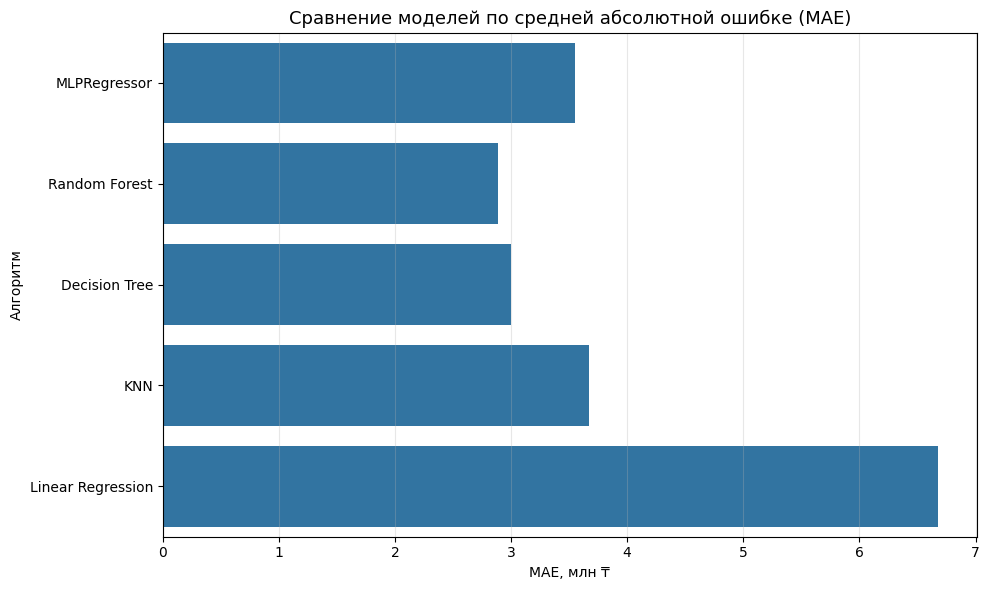

In [106]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=models_comparison_15,
    x='MAE, млн ₸',
    y='Модель'
)

plt.title(
    'Сравнение моделей по средней абсолютной ошибке (MAE)',
    fontsize=13
)

plt.xlabel('MAE, млн ₸')
plt.ylabel('Алгоритм')

plt.grid(axis='x', alpha=0.3)
plt.tight_layout()

plt.show()

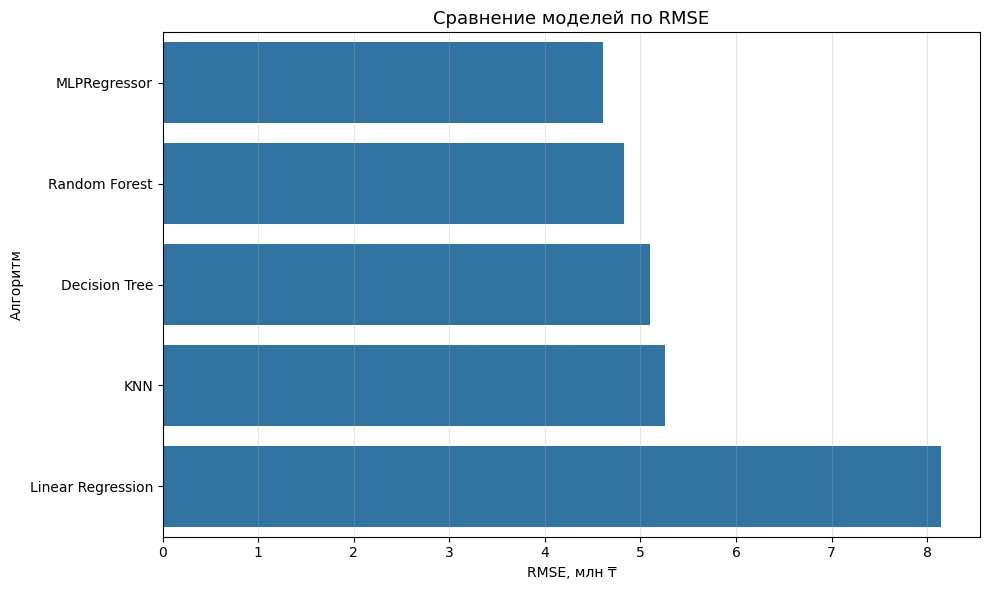

In [107]:
#Сравниваем RMSE
plt.figure(figsize=(10, 6))

sns.barplot(
    data=models_comparison_15,
    x='RMSE, млн ₸',
    y='Модель'
)

plt.title(
    'Сравнение моделей по RMSE',
    fontsize=13
)

plt.xlabel('RMSE, млн ₸')
plt.ylabel('Алгоритм')

plt.grid(axis='x', alpha=0.3)
plt.tight_layout()

plt.show()

RMSE сильнее учитывает крупные ошибки. Поэтому эта метрика особенно важна для оценки прогнозирования дорогих квартир.

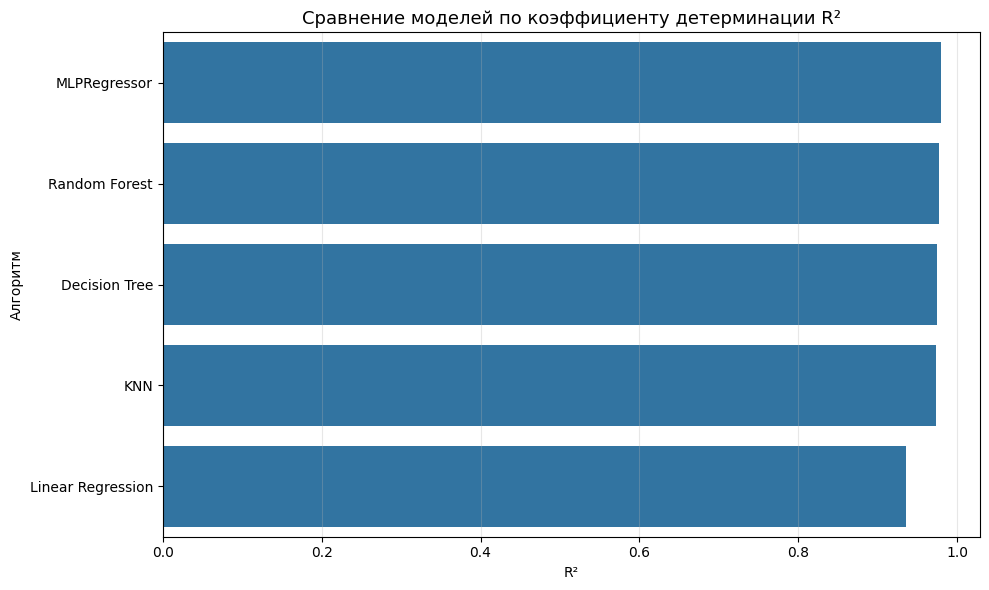

In [108]:
#Сравниваем R²
plt.figure(figsize=(10, 6))

sns.barplot(
    data=models_comparison_15,
    x='R²',
    y='Модель'
)

plt.title(
    'Сравнение моделей по коэффициенту детерминации R²',
    fontsize=13
)

plt.xlabel('R²')
plt.ylabel('Алгоритм')

plt.grid(axis='x', alpha=0.3)
plt.tight_layout()

plt.show()

Чем выше R², тем лучше модель объясняет изменчивость стоимости квартир. При этом высокий R² сам по себе не означает, что модель имеет минимальную ошибку в тенге.

In [109]:
#Определяем победителя по каждой метрике
best_mae_model = models_comparison_15.loc[
    models_comparison_15['MAE, млн ₸'].idxmin()
]

best_rmse_model = models_comparison_15.loc[
    models_comparison_15['RMSE, млн ₸'].idxmin()
]

best_r2_model = models_comparison_15.loc[
    models_comparison_15['R²'].idxmax()
]

print('Лучшая модель по MAE:')
print(best_mae_model['Модель'],
      round(best_mae_model['MAE, млн ₸'], 3))

print('\nЛучшая модель по RMSE:')
print(best_rmse_model['Модель'],
      round(best_rmse_model['RMSE, млн ₸'], 3))

print('\nЛучшая модель по R²:')
print(best_r2_model['Модель'],
      round(best_r2_model['R²'], 4))

Лучшая модель по MAE:
Random Forest 2.891

Лучшая модель по RMSE:
MLPRegressor 4.607

Лучшая модель по R²:
MLPRegressor 0.9795


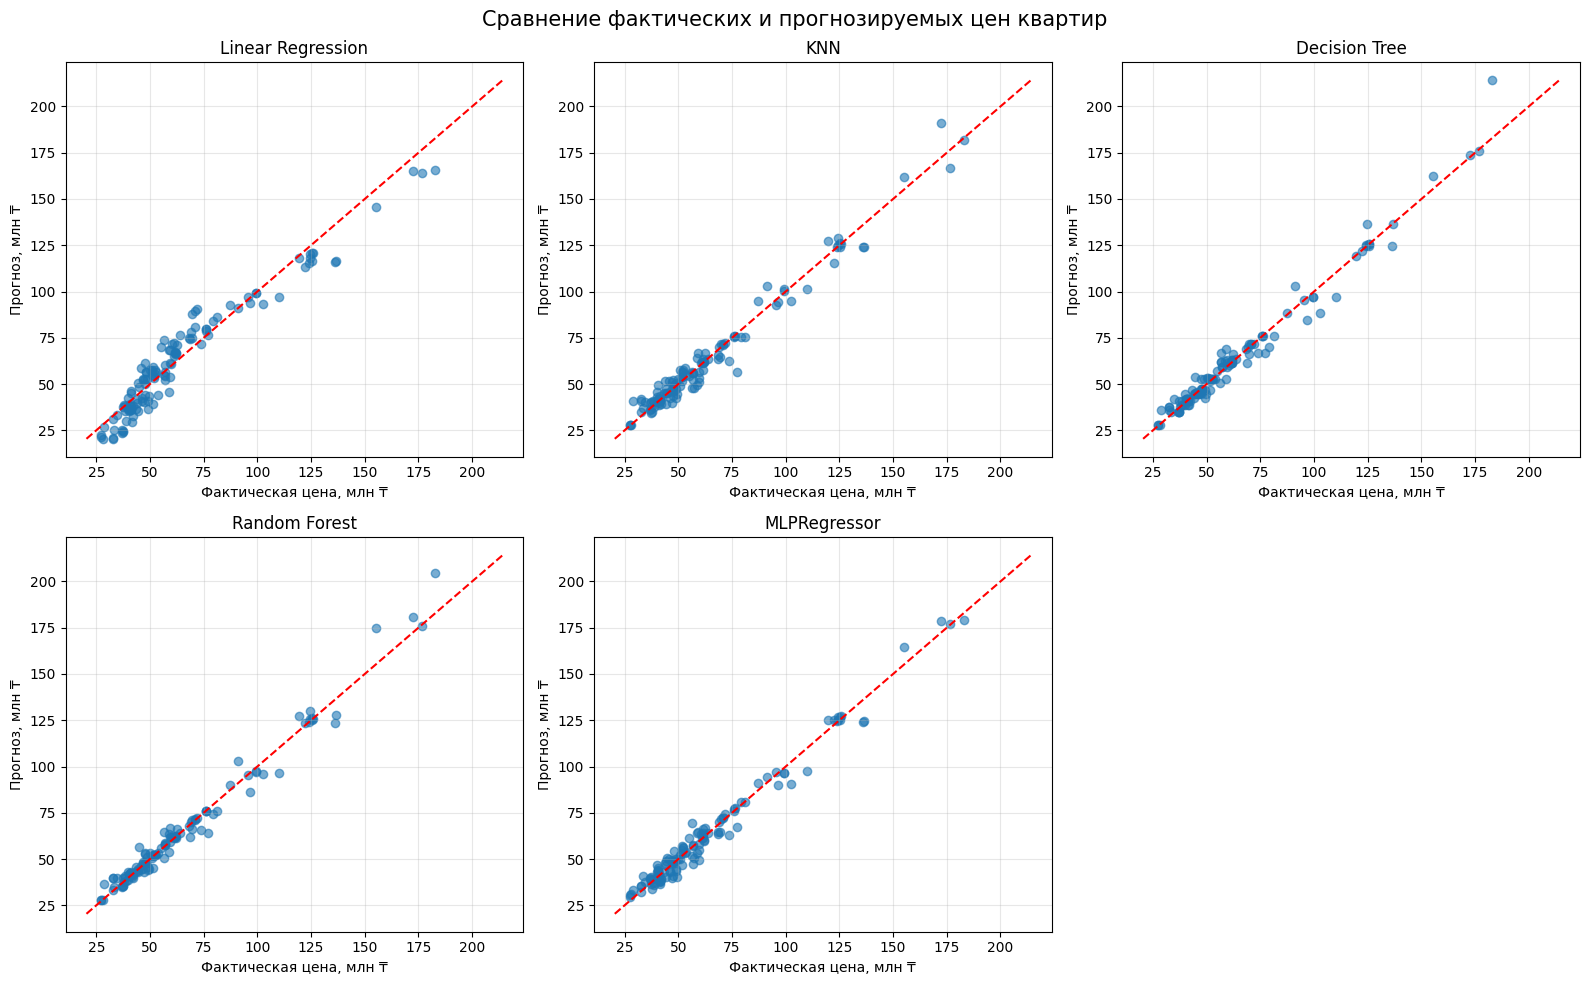

In [110]:
#Сравниваем фактические и прогнозируемые цены
fig, axes = plt.subplots(
    2, 3,
    figsize=(16, 10)
)

axes = axes.flatten()

minimum = min(
    y_test.min(),
    min(pred.min() for pred in predictions_15.values())
)

maximum = max(
    y_test.max(),
    max(pred.max() for pred in predictions_15.values())
)

for i, (name, predictions) in enumerate(
    predictions_15.items()
):

    axes[i].scatter(
        y_test,
        predictions,
        alpha=0.6
    )

    axes[i].plot(
        [minimum, maximum],
        [minimum, maximum],
        'r--'
    )

    axes[i].set_title(name)
    axes[i].set_xlabel('Фактическая цена, млн ₸')
    axes[i].set_ylabel('Прогноз, млн ₸')
    axes[i].grid(alpha=0.3)

axes[5].axis('off')

plt.suptitle(
    'Сравнение фактических и прогнозируемых цен квартир',
    fontsize=15
)

plt.tight_layout()
plt.show()

*Интерпретация:* чем ближе облако точек к диагональной линии, тем точнее прогнозы соответствующей модели.

In [111]:
# Сравнение средней относительной ошибки

relative_errors = []

for name, predictions in predictions_15.items():

    errors_percent = (
        np.abs(y_test.values - predictions) /
        np.maximum(np.abs(y_test.values), 1e-10)
    ) * 100

    relative_errors.append({
        'Модель': name,
        'Средняя ошибка, %': errors_percent.mean(),
        'Медианная ошибка, %': np.median(errors_percent)
    })

relative_errors_df = pd.DataFrame(relative_errors)

display(relative_errors_df.round(2))

,Модель,"Средняя ошибка, %","Медианная ошибка, %"
0,Linear Regression,11.98,9.04
1,KNN,6.32,4.33
2,Decision Tree,4.88,2.96
3,Random Forest,4.56,2.44
4,MLPRegressor,6.29,5.94


Это дополнение полезно, поскольку позволяет оценить ошибку относительно стоимости квартиры, а не только в абсолютных миллионах тенге.

In [112]:
final_comparison = models_comparison_15.merge(
    relative_errors_df,
    on='Модель'
)

final_comparison = final_comparison.sort_values(
    'RMSE, млн ₸'
).reset_index(drop=True)

display(
    final_comparison.style.format({
        'MAE, млн ₸': '{:.3f}',
        'RMSE, млн ₸': '{:.3f}',
        'R²': '{:.4f}',
        'Средняя ошибка, %': '{:.2f}',
        'Медианная ошибка, %': '{:.2f}'
    })
)

,Модель,"MAE, млн ₸","RMSE, млн ₸",R²,"Средняя ошибка, %","Медианная ошибка, %"
0,MLPRegressor,3.547,4.607,0.9795,6.29,5.94
1,Random Forest,2.891,4.826,0.9775,4.56,2.44
2,Decision Tree,2.999,5.102,0.9749,4.88,2.96
3,KNN,3.671,5.261,0.9733,6.32,4.33
4,Linear Regression,6.677,8.147,0.9360,11.98,9.04


**1. Какая модель показала лучший результат?** По MAE лучший Random Forest (2,89 млн ₸), по RMSE и R² — MLPRegressor (4,61 млн ₸ и 0,980), Random Forest на втором месте (4,81 и 0,978).

**2. Какая модель имеет наименьшую MAE?** Random Forest — 2,89 млн ₸. Далее дерево решений (3,00), MLP (3,55), KNN (3,67) и линейная регрессия (6,68).

**3. Какая модель лучше справляется с большими ошибками?** MLP: у неё наименьшая RMSE (4,61) и наименьшая максимальная ошибка (13,0 млн ₸). У леса максимальная ошибка 21,8, у KNN 20,5, у дерева 31,3 млн ₸.

**4. Какая модель лучше объясняет изменение стоимости?** MLP (R² = 0,980), затем Random Forest (0,978), дерево (0,975), KNN (0,973) и линейная регрессия (0,936).

**5. Почему результаты моделей отличаются?** Алгоритмы по-разному выявляют закономерности. Линейная регрессия предполагает один и тот же «тариф» за м² во всех комплексах, а на деле он различается: около 0,64 млн ₸ в Jibek Joly, 0,76 в Arena City Balance, 0,83 в Saulet и 1,30 в Taumura, поэтому она ошибается сильнее всех. KNN учитывает сходство объектов, дерево формирует цепочки условий, лес усредняет множество деревьев, а MLP выявляет нелинейные зависимости.

**6. Можно ли считать модель с наибольшим R² автоматически лучшей?** Нет. У MLP R² наибольший, но типичная относительная ошибка у неё 5,9% против 2,4% у Random Forest, а по кросс-валидации она заметно хуже (RMSE 5,94 против 3,33). Поэтому оцениваем модели по нескольким метрикам.

**7. Какие ограничения имеет исследование?** Данные охватывают только 4 жилых комплекса (9 корпусов), поэтому результаты нельзя переносить на весь рынок Алматы.

**8. Какую модель целесообразно использовать дальше?** Random Forest. Для окончательной проверки её нужно протестировать на новых данных, в первую очередь на комплексах, которых нет в обучении.

In [113]:
# Автоматическая интерпретация результатов

print('ИТОГИ СРАВНЕНИЯ МОДЕЛЕЙ\n')

print(
    'Лучшая модель по MAE:',
    best_mae_model['Модель'],
    '| MAE =',
    round(best_mae_model['MAE, млн ₸'], 3),
    'млн ₸'
)

print(
    '\nЛучшая модель по RMSE:',
    best_rmse_model['Модель'],
    '| RMSE =',
    round(best_rmse_model['RMSE, млн ₸'], 3),
    'млн ₸'
)

print(
    '\nЛучшая модель по R²:',
    best_r2_model['Модель'],
    '| R² =',
    round(best_r2_model['R²'], 4)
)

winner = models_comparison_15.iloc[0]

print('\nОБЩИЙ РЕЗУЛЬТАТ:')
print('Модель с минимальной RMSE:', winner['Модель'])
print('Средняя абсолютная ошибка:',
      round(winner['MAE, млн ₸'], 3), 'млн ₸')
print('Среднеквадратичная ошибка:',
      round(winner['RMSE, млн ₸'], 3), 'млн ₸')
print('Коэффициент детерминации:',
      round(winner['R²'], 4))

ИТОГИ СРАВНЕНИЯ МОДЕЛЕЙ

Лучшая модель по MAE: Random Forest | MAE = 2.891 млн ₸

Лучшая модель по RMSE: MLPRegressor | RMSE = 4.607 млн ₸

Лучшая модель по R²: MLPRegressor | R² = 0.9795

ОБЩИЙ РЕЗУЛЬТАТ:
Модель с минимальной RMSE: MLPRegressor
Средняя абсолютная ошибка: 3.547 млн ₸
Среднеквадратичная ошибка: 4.607 млн ₸
Коэффициент детерминации: 0.9795


## Сравнение моделей

| Модель | MAE, млн ₸ | RMSE, млн ₸ | R² | CV RMSE, млн ₸ | Примечание |
|---|---|---|---|---|---|
| Linear Regression | 6,68 | 8,15 | 0,936 | 8,55 | Не учитывает различие цены за м² между комплексами |
| KNN (k = 4, со StandardScaler) | 3,67 | 5,26 | 0,973 | 5,35 | k найден по тесту; GridSearchCV (k = 3, distance, p = 1) даёт MAE 3,38 и RMSE 5,23 |
| Decision Tree (глубина 8) | 3,00 | 5,10 | 0,975 | 3,96 | Почти то же качество, что при глубине 10 (RMSE 5,08), но проще; одна ошибка 31 млн ₸ |
| Random Forest (200 деревьев, глубина 9) | 2,89 | 4,81 | 0,978 | 3,33 | Лучшая MAE и лучшая кросс-валидация; мало чувствителен к параметрам |
| MLPRegressor (50, 25) | 3,55 | 4,61 | 0,980 | 5,94 | Лучшие RMSE и R² на тесте, но в кросс-валидации хуже и типичная ошибка выше |
| Простая модель (среднее) | 23,26 | 32,20 | −0,000 | — | Ориентир: всегда предсказывает среднюю цену |

MAE, RMSE и R² рассчитаны на тестовой выборке (125 квартир). CV RMSE — среднее по 5-кратной кросс-валидации на обучающей выборке; она не использует тест и показывает устойчивость модели. Основная метрика — RMSE (крупные ошибки в цене квартиры особенно нежелательны), дополнительные — MAE и R².

## 12. Выбор итоговой модели

В качестве итоговой модели выбран **Random Forest Regressor** (200 деревьев, максимальная глубина 9). Модель показала на тесте MAE = 2,89 млн ₸, RMSE = 4,81 млн ₸ и R² = 0,978.

Она выбрана потому, что:
1. у неё наименьшая MAE и наименьшая типичная ошибка: медиана 1,32 млн ₸, около 2,4% от цены;
2. она лучшая по кросс-валидации на обучающей выборке (RMSE 3,33 против 3,96 у дерева, 5,35 у KNN и 5,94 у MLP), то есть меньше зависит от удачного разбиения;
3. она мало чувствительна к настройке: GridSearchCV дал практически тот же результат, что и исходные 100 деревьев.

Нейросеть MLP получила лучшие RMSE (4,61) и R² (0,980) на тесте и точнее прогнозирует дорогие квартиры, но её типичная ошибка более чем вдвое больше (медиана 5,9%), а по кросс-валидации она заметно слабее. Разница в RMSE между MLP и Random Forest (0,2 млн ₸) невелика для тестовой выборки из 125 квартир, поэтому предпочтение отдано более стабильной модели.

## Интерпретация результата

**Что означает результат.** В среднем модель ошибается на 2,89 млн ₸ при средней цене квартиры около 64 млн ₸; типичная (медианная) ошибка составляет 1,32 млн ₸, или около 2,4% цены. R² = 0,978 означает, что модель объясняет около 98% разброса цен.

**Важные признаки.** Самый важный признак — площадь (важность 0,57), далее класс «Бизнес» (0,18), широта (0,17) и число комнат (0,05); остальные признаки имеют важность меньше 0,01. Широта и класс по сути указывают на жилой комплекс, поэтому цена определяется прежде всего размером квартиры и комплексом. Важность признаков показывает, на что опирается модель, но не доказывает причинную связь.

**Ошибки модели.** Ошибка больше 10 млн ₸ только у 8 из 125 тестовых квартир, максимальная ошибка 21,8 млн ₸. Хуже всего прогнозируются дорогие квартиры: для топ-10% по цене средняя ошибка 6,17 млн ₸, для остальных 2,50. Таких квартир (бизнес-класс Taumura) в данных мало, и у них меньше похожих соседей.

**Полезность и применимость.** Модель подходит для ориентировочной оценки цены квартиры в изученных комплексах и для поиска переоценённых или недооценённых предложений. На реальных данных других комплексов её применять нельзя без проверки: на новом ЖК качество резко падает (см. раздел 14).

## Ограничения

1. **Малое число комплексов.** В данных 623 квартиры только из 4 жилых комплексов (9 корпусов), поэтому результаты нельзя переносить на весь рынок Алматы.
2. **Плохая работа на новых комплексах.** Признаки `class`, `latitude`, `longitude`, `dist_center_km` фактически определяют комплекс. В дополнительной проверке мы поочерёдно исключали из обучения один комплекс и тестировали на нём: ошибка Random Forest составила от 5,6 млн ₸ (Arena City Balance) до 47,6 млн ₸ (Taumura), а R² для трёх из четырёх комплексов был отрицательным. Taumura — единственный бизнес-класс с ценой около 1,3 млн ₸ за м² (против 0,64–0,83 у остальных), поэтому для него экстраполяция особенно трудна.
3. **Оптимистичная оценка при случайном разбиении.** В каждом корпусе много квартир с одинаковой площадью и числом комнат (таких повторов не менее 346 из 623), и при случайном разбиении их «двойники» попадают и в обучение, и в тест.
4. **Подбор параметров по тесту.** Значения k, глубину деревьев и число деревьев в отдельных разделах мы выбирали по тестовой выборке, поэтому эти оценки слегка завышены; корректная оценка — через GridSearchCV и кросс-валидацию.
5. **Цены из прайс-листов.** Данные отражают заявленные цены на одну дату, а не фактические сделки.
6. **Мало дорогих квартир.** Бизнес-класс и крупные квартиры представлены слабо, поэтому именно для них ошибка максимальна.
7. **Недостаточно признаков.** Нет отделки, вида из окна, срока сдачи, условий рассрочки. Кроме того, 42 забронированные квартиры без цены удалены, что могло слегка сместить распределение.

## Итоговый вывод

В проекте решалась задача прогнозирования стоимости квартир в новостройках Алматы. Использован датасет из 665 квартир четырёх жилых комплексов (девяти корпусов); после удаления 42 квартир без цены осталось 623. Целевая переменная — цена в млн ₸, тип задачи — регрессия. Данные были очищены, служебные признаки исключены, класс жилья закодирован через `get_dummies`, а признаки для KNN и нейросети масштабированы внутри Pipeline. Выборка разделена на обучающую (498 квартир) и тестовую (125 квартир). Обучено пять моделей: линейная регрессия, KNN, дерево решений, Random Forest и MLPRegressor; простая модель, предсказывающая среднюю цену, использована как ориентир. Качество оценивалось по MAE, RMSE и R², а для надёжности дополнительно применялись кросс-валидация и GridSearchCV. Все нелинейные модели существенно превзошли линейную регрессию (RMSE 4,6–5,3 против 8,1 млн ₸). Итоговой выбран Random Forest: MAE 2,89 млн ₸, RMSE 4,81 млн ₸, R² 0,978, типичная ошибка около 2,4% цены. Наиболее важными признаками оказались площадь, класс жилья и расположение комплекса, а хуже всего модель прогнозирует дорогие квартиры бизнес-класса. Главное ограничение — малое число комплексов: на новом ЖК, которого не было в обучении, модель работает плохо. Для улучшения нужно собрать данные по большему числу ЖК, добавить признаки (отделка, срок сдачи, вид) и проверять модель на комплексах, скрытых при обучении. Цель проекта достигнута: получена модель, пригодная для ориентировочной оценки цены квартир в изученных комплексах.

In [115]:
# Кросс-валидация итоговых моделей (только обучающая выборка)
cv_rows = []
for name, model in models_15.items():
    s = -cross_val_score(model, X_train, y_train, cv=5, scoring='neg_root_mean_squared_error')
    cv_rows.append({'Модель': name, 'CV RMSE, млн ₸': s.mean()})
display(pd.DataFrame(cv_rows).round(3))

# Проверка на новом ЖК: поочерёдно исключаем один комплекс из обучения
from sklearn.model_selection import LeaveOneGroupOut
groups = df['source']
rows = []
for tr, te in LeaveOneGroupOut().split(X, y, groups):
    m = RandomForestRegressor(n_estimators=200, max_depth=9, random_state=42)
    m.fit(X.iloc[tr], y.iloc[tr])
    mae, rmse, r2 = evaluate(y.iloc[te], m.predict(X.iloc[te]))
    rows.append({'ЖК вне обучения': groups.iloc[te].iloc[0], 'MAE': mae, 'RMSE': rmse, 'R2': r2})
display(pd.DataFrame(rows).round(2))

# Повторы квартир внутри корпуса (одинаковая площадь и число комнат)
print('Повторов:', df.duplicated(['complex', 'area', 'rooms']).sum(), 'из', len(df))

,Модель,"CV RMSE, млн ₸"
0,Linear Regression,8.549
1,KNN,5.353
2,Decision Tree,3.898
3,Random Forest,3.336
4,MLPRegressor,5.935


,ЖК вне обучения,MAE,RMSE,R2
0,ARENA_CITY_BALANCE.csv,5.48,7.26,0.67
1,JIBEK_JOLY.csv,36.33,37.39,-12.87
2,SAULET.csv,19.75,20.68,-1.46
3,TAUMURA.csv,47.50,54.08,-0.86


Повторов: 346 из 623
